# E-Commerce Business Analytics

### Python Data Analytics Portfolio Project

**Tools:** Python | NumPy | Pandas | Matplotlib | Seaborn

**Dataset:** 20,050 E-Commerce Transactions

**Objective:** Analyze sales, profitability, customers, products, operations, and business risks to generate actionable business insights.


## 1. Business Objective

The objective of this project is to analyze e-commerce transaction data and identify key patterns in sales, profitability, customer behavior, product performance, regional performance, shipping operations, and payment methods.

The analysis focuses on answering business questions such as:

* How are sales and profits changing over time?
* Which categories and products generate the most revenue and profit?
* Which customers contribute the most value to the business?
* Which customers or products represent potential business risks?
* Which regions and operational areas require attention?
* How do shipping and payment methods affect business performance?
* Where are the major opportunities to improve revenue and profitability?

The final analysis converts the findings into **business insights and actionable recommendations**.


## 2. Dataset Overview

The dataset contains e-commerce transaction-level information covering customers, products, sales, profit, quantity, discounts, regions, shipping methods, and payment methods.

### Dataset Characteristics

* **Original records:** 20,050
* **Final records after duplicate removal:** 20,000
* **Columns:** 16
* **Data type:** Transaction-level e-commerce data
* **Primary analysis areas:** Sales, Profitability, Customers, Products, Regions, Shipping, Payment, and Time Trends


In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("data/ecommerce_python.csv")


df.shape

(20050, 16)

In [2]:
df.head()

,Order_ID,Order_Date,Customer_ID,Customer_Name,Category,Sub_Category,Product_Name,Region,State,Sales,Quantity,Discount,Profit,Ship_Mode,Ship_Date,Payment_Mode
0,ORD100000,28-01-2024,2601,Customer_2601,Furniture,Furnishings,Cushion Set,South,Tamil Nadu,213.39,1,0.05,16.13,Same Day,29-01-2024,Debit Card
1,ORD100001,05-07-2024,4999,Customer_4999,Clothing,Kids,Kids Shoes,West,Rajasthan,290.89,2,0.20,47.88,Standard Class,12-07-2024,UPI
2,ORD100002,30-10-2025,1887,Customer_1887,Electronics,Accessories,Keyboard,East,Assam,96.36,2,0.25,-3.57,Standard Class,02-11-2025,Debit Card
3,ORD100003,13-09-2024,1993,Customer_1993,Office Supplies,Appliances,Air Purifier,East,Assam,1555.26,3,0.15,136.22,Standard Class,16-09-2024,Credit Card
4,ORD100004,29-10-2024,4439,Customer_4439,Home & Kitchen,Cleaning,Mop,North,Haryana,143.77,1,0.10,-0.18,Standard Class,31-10-2024,Debit Card


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20050 entries, 0 to 20049
Data columns (total 16 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       20050 non-null  str    
 1   Order_Date     20050 non-null  str    
 2   Customer_ID    20050 non-null  int64  
 3   Customer_Name  19930 non-null  str    
 4   Category       20050 non-null  str    
 5   Sub_Category   20050 non-null  str    
 6   Product_Name   20050 non-null  str    
 7   Region         20050 non-null  str    
 8   State          19970 non-null  str    
 9   Sales          20050 non-null  float64
 10  Quantity       20050 non-null  int64  
 11  Discount       20050 non-null  float64
 12  Profit         20050 non-null  float64
 13  Ship_Mode      20050 non-null  str    
 14  Ship_Date      19990 non-null  str    
 15  Payment_Mode   19970 non-null  str    
dtypes: float64(3), int64(2), str(11)
memory usage: 2.4 MB


## 3. Data Cleaning & Validation

Before performing business analysis, the dataset was inspected and cleaned to improve data quality and ensure reliable analytical results.

The main data-quality issues identified were:

* Duplicate transaction records
* Missing customer names
* Missing states
* Missing payment methods
* Missing shipping dates
* Zero quantities
* Invalid discount values
* Negative sales values
* Date columns stored as text
* Inconsistent text formatting


In [4]:
print("Duplicate rows:", df.duplicated().sum())

print("Missing values:")
print(df.isna().sum())

Duplicate rows: 50
Missing values:
Order_ID           0
Order_Date         0
Customer_ID        0
Customer_Name    120
Category           0
Sub_Category       0
Product_Name       0
Region             0
State             80
Sales              0
Quantity           0
Discount           0
Profit             0
Ship_Mode          0
Ship_Date         60
Payment_Mode      80
dtype: int64


In [5]:
df = df.drop_duplicates()

df["Customer_Name"] = df["Customer_Name"].fillna("Unknown")
df["State"] = df["State"].fillna("Unknown")
df["Payment_Mode"] = df["Payment_Mode"].fillna("Unknown")

df["Category"] = df["Category"].str.strip().str.title()
df["Region"] = df["Region"].str.strip()
df["Payment_Mode"] = df["Payment_Mode"].str.strip()

df["Order_Date"] = pd.to_datetime(
    df["Order_Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

df["Ship_Date"] = pd.to_datetime(
    df["Ship_Date"],
    format="%d-%m-%Y",
    errors="coerce"
)

df["Quantity"] = df["Quantity"].replace(0, np.nan)

df.loc[df["Discount"] > 1, "Discount"] = np.nan

df.loc[df["Sales"] < 0, "Sales"] = np.nan

In [6]:
print("Rows after cleaning:", len(df))
print("Duplicate rows:", df.duplicated().sum())
print("Negative sales:", (df["Sales"] < 0).sum())
print("Zero quantity:", (df["Quantity"] == 0).sum())
print("Invalid discount:", (df["Discount"] > 1).sum())

Rows after cleaning: 20000
Duplicate rows: 0
Negative sales: 0
Zero quantity: 0
Invalid discount: 0


## 4. Overall Business Performance

### Business Question

What is the overall financial and operational performance of the e-commerce business?

The analysis focuses on total sales, total profit, profit margin, orders, customers, quantity sold, and average order value.


In [7]:
Total_Sales = df["Sales"].sum()
Total_Profit = df["Profit"].sum()
Profit_Margin = (Total_Profit / Total_Sales) * 100
Total_Orders = df["Order_ID"].nunique()
Total_Customers = df["Customer_ID"].nunique()
Total_Quantity = df["Quantity"].sum()
Average_Order_Value = Total_Sales / Total_Orders

Overall_KPIs = pd.DataFrame({
    "KPI": [
        "Total Sales",
        "Total Profit",
        "Profit Margin %",
        "Total Orders",
        "Total Customers",
        "Total Quantity",
        "Average Order Value"
    ],
    "Value": [
        Total_Sales,
        Total_Profit,
        Profit_Margin,
        Total_Orders,
        Total_Customers,
        Total_Quantity,
        Average_Order_Value
    ]
})

Overall_KPIs["Value"] = Overall_KPIs["Value"].apply(
    lambda x: f"{x:,.2f}"
)

Overall_KPIs

,KPI,Value
0,Total Sales,"15,172,075.47"
1,Total Profit,"1,296,689.72"
2,Profit Margin %,8.55
3,Total Orders,"20,000.00"
4,Total Customers,"3,982.00"
5,Total Quantity,"63,617.00"
6,Average Order Value,758.60


### Business Insight

* The business generated approximately **₹1.52 crore in total sales** across 20,000 orders.
* Total profit was approximately **₹12.97 lakh**, resulting in an overall **profit margin of 8.55%**.
* The average order value was approximately **₹758.60**, indicating the average revenue generated per order.


## 5. Monthly Sales & Profit Trend

### Business Question

How do sales and profit change over time, and are there identifiable growth or seasonal patterns?


In [8]:
Portfolio_Monthly = (
    df.assign(
        Year=df["Order_Date"].dt.year,
        Month=df["Order_Date"].dt.month
    )
    .groupby(["Year", "Month"])
    .agg(
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Total_Orders=("Order_ID", "nunique")
    )
    .reset_index()
)

Portfolio_Monthly["Year_Month"] = pd.to_datetime(
    Portfolio_Monthly["Year"].astype(str)
    + "-"
    + Portfolio_Monthly["Month"].astype(str)
    + "-01"
)

Portfolio_Monthly["Profit_Margin_%"] = (
    Portfolio_Monthly["Total_Profit"]
    / Portfolio_Monthly["Total_Sales"]
) * 100

Portfolio_Monthly["AOV"] = (
    Portfolio_Monthly["Total_Sales"]
    / Portfolio_Monthly["Total_Orders"]
)

Portfolio_Monthly["MoM_Sales_Growth_%"] = (
    Portfolio_Monthly["Total_Sales"].pct_change()
) * 100

Portfolio_Monthly.head()

,Year,Month,Total_Sales,Total_Profit,Total_Orders,Year_Month,Profit_Margin_%,AOV,MoM_Sales_Growth_%
0,2024,1,681982.34,63291.76,898,2024-01-01,9.280557,759.445813,NaN
1,2024,2,642615.95,54047.18,848,2024-02-01,8.410495,757.801828,-5.772347
2,2024,3,599209.19,56040.77,826,2024-03-01,9.352455,725.434855,-6.754697
3,2024,4,584036.92,46908.88,807,2024-04-01,8.031835,723.713656,-2.532049
4,2024,5,641916.91,53850.21,867,2024-05-01,8.388969,740.388593,9.910331


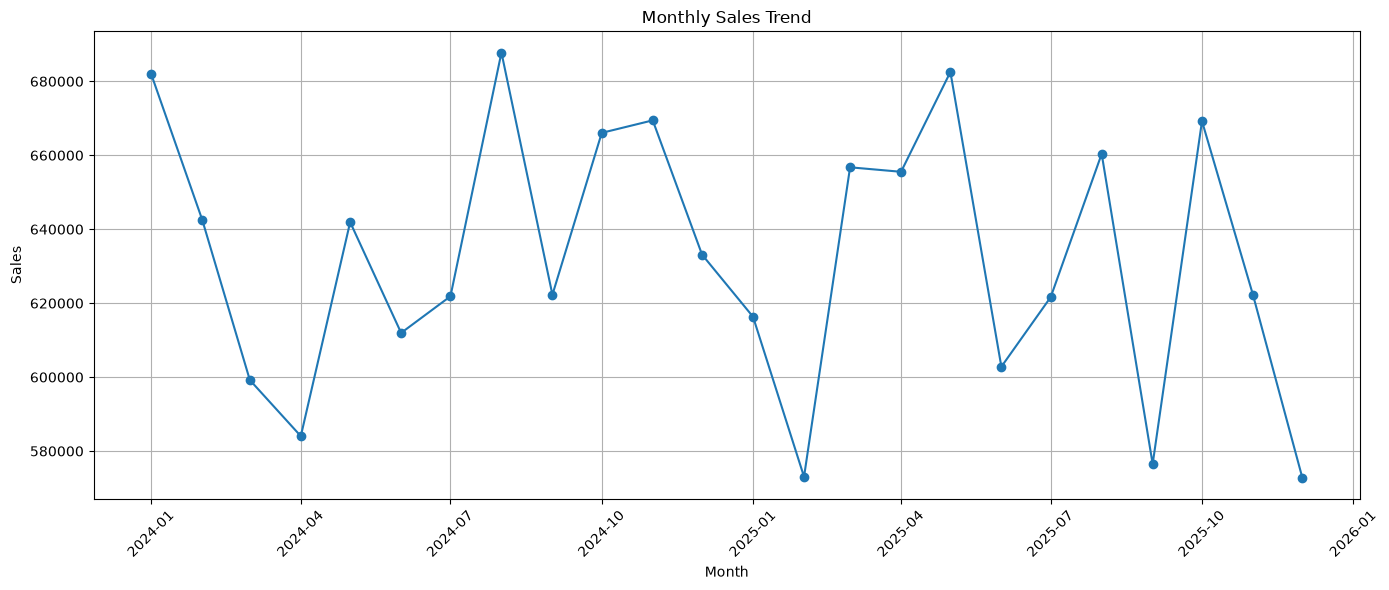

In [9]:
plt.figure(figsize=(14, 6))

plt.plot(
    Portfolio_Monthly["Year_Month"],
    Portfolio_Monthly["Total_Sales"],
    marker="o"
)

plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.grid()

plt.tight_layout()
plt.show()

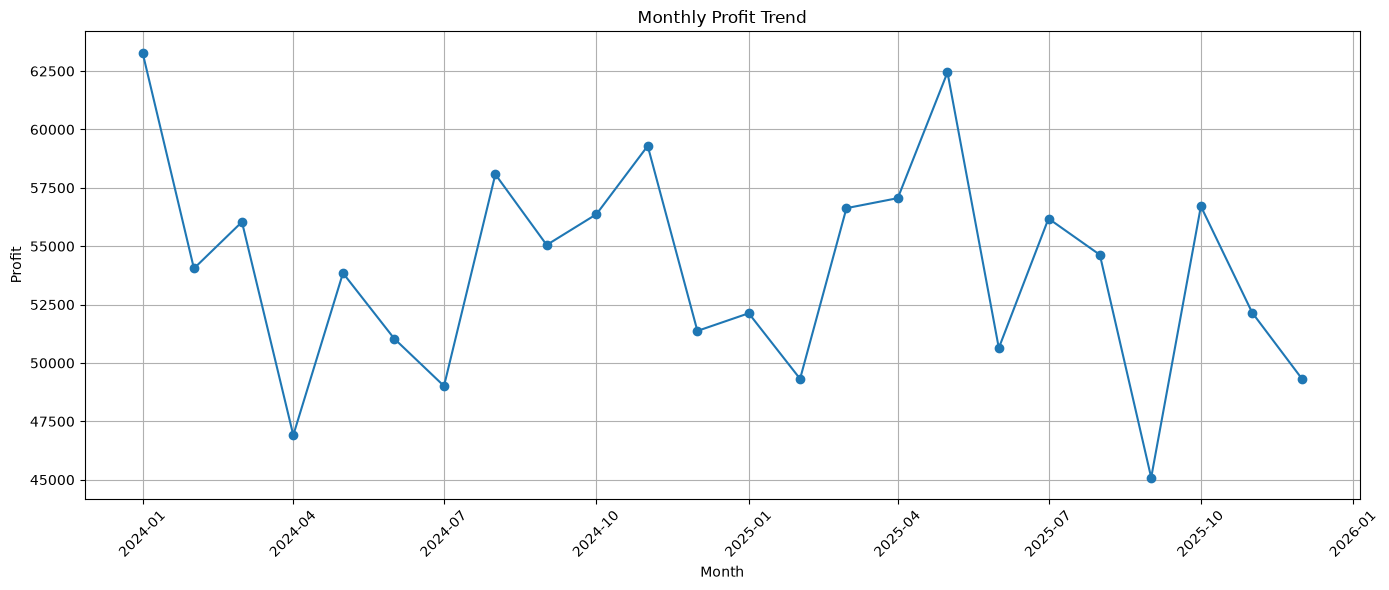

In [10]:
plt.figure(figsize=(14, 6))

plt.plot(
    Portfolio_Monthly["Year_Month"],
    Portfolio_Monthly["Total_Profit"],
    marker="o"
)

plt.title("Monthly Profit Trend")
plt.xlabel("Month")
plt.ylabel("Profit")
plt.xticks(rotation=45)
plt.grid()

plt.tight_layout()
plt.show()

### Business Insights

* Sales showed a **mixed month-to-month pattern** rather than a consistent upward or downward trend.
* **August 2024** recorded the highest monthly sales during the analyzed period.
* **December 2025** recorded the lowest monthly sales during the analyzed period.
* Monthly profit also followed a **mixed pattern**, broadly moving with changes in monthly sales.
* The variation in monthly performance suggests that sales and profitability should be monitored over time to identify recurring seasonal or demand-related patterns.


### Business Action

Monitor monthly sales and profit trends to identify recurring high- and low-performing periods. Further analysis of category, customer, and product performance during these periods can help identify the factors driving monthly fluctuations.


## 6. Category & Sub-Category Performance

### Business Question

Which product categories contribute the most to revenue and profit, and are high-sales categories also sufficiently profitable?


In [11]:
Portfolio_Category = (
    df.groupby("Category")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Orders=("Order_ID", "nunique")
      )
      .reset_index()
)

Portfolio_Category["Profit_Margin_%"] = (
    Portfolio_Category["Total_Profit"]
    / Portfolio_Category["Total_Sales"]
) * 100

Portfolio_Category["AOV"] = (
    Portfolio_Category["Total_Sales"]
    / Portfolio_Category["Total_Orders"]
)

Portfolio_Category["Sales_Contribution_%"] = (
    Portfolio_Category["Total_Sales"]
    / Portfolio_Category["Total_Sales"].sum()
) * 100

Portfolio_Category["Profit_Contribution_%"] = (
    Portfolio_Category["Total_Profit"]
    / Portfolio_Category["Total_Profit"].sum()
) * 100

display(
    Portfolio_Category.style.format({
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Profit_Margin_%": "{:.2f}%",
        "AOV": "₹{:,.2f}",
        "Sales_Contribution_%": "{:.2f}%",
        "Profit_Contribution_%": "{:.2f}%"
    })
)


,Category,Total_Sales,Total_Profit,Total_Orders,Profit_Margin_%,AOV,Sales_Contribution_%,Profit_Contribution_%
0,Clothing,"₹2,509,660.86","₹335,488.42",3258,13.37%,₹770.31,16.54%,25.87%
1,Electronics,"₹3,478,032.23","₹137,504.96",4679,3.95%,₹743.33,22.92%,10.60%
2,Furniture,"₹3,104,651.58","₹213,749.58",4020,6.88%,₹772.30,20.46%,16.48%
3,Home & Kitchen,"₹2,686,331.54","₹237,605.61",3582,8.84%,₹749.95,17.71%,18.32%
4,Office Supplies,"₹3,393,399.26","₹372,341.15",4461,10.97%,₹760.68,22.37%,28.71%


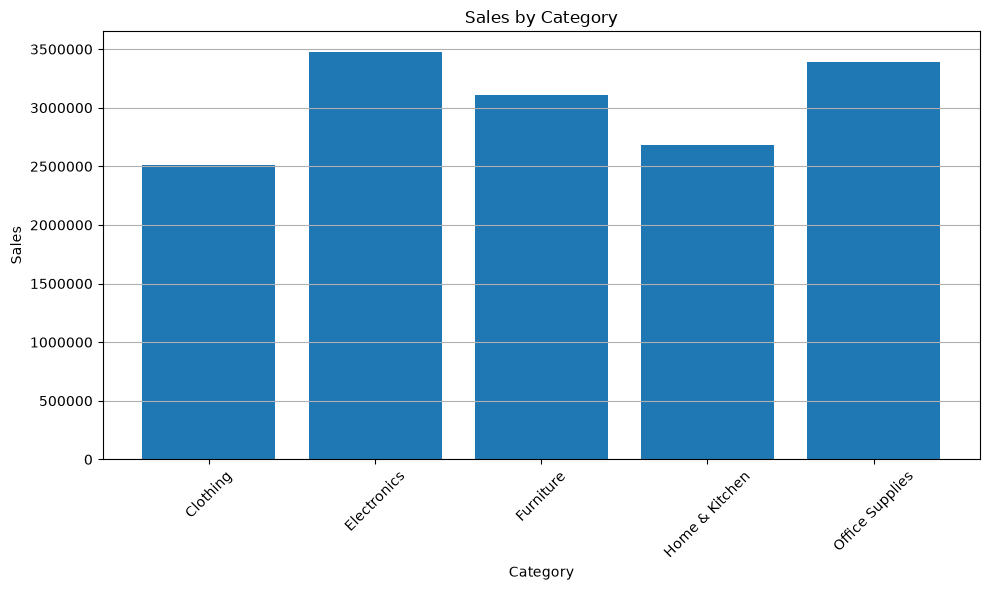

In [12]:
plt.figure(figsize=(10, 6))

plt.bar(
    Portfolio_Category["Category"],
    Portfolio_Category["Total_Sales"]
)

plt.title("Sales by Category")
plt.xlabel("Category")
plt.ylabel("Sales")
plt.xticks(rotation=45)
plt.ticklabel_format(style="plain", axis="y")
plt.grid(axis="y")

plt.tight_layout()
plt.show()

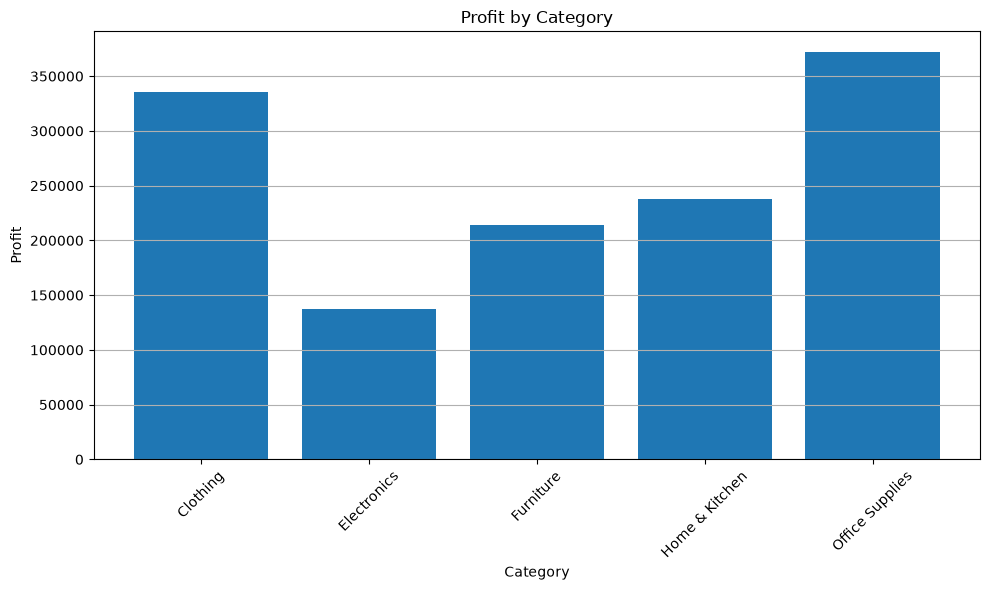

In [13]:
plt.figure(figsize=(10, 6))

plt.bar(
    Portfolio_Category["Category"],
    Portfolio_Category["Total_Profit"]
)

plt.title("Profit by Category")
plt.xlabel("Category")
plt.ylabel("Profit")
plt.xticks(rotation=45)

plt.ticklabel_format(
    style="plain",
    axis="y",
    useOffset=False
)

plt.grid(axis="y")

plt.tight_layout()
plt.show()

### Business Insights

* **Electronics** generated the highest total sales but had the **lowest profit margin** among the categories.
* **Clothing** generated the lowest total sales but had the **highest profit margin**.
* The category generating the most revenue was therefore **not** the category with the highest profitability.
* This indicates that revenue contribution and profitability should be evaluated together rather than using sales alone to assess category performance.


### Business Action

Investigate the pricing, discount levels, product mix, and cost structure of Electronics to understand why its high sales volume results in a comparatively lower margin. At the same time, evaluate whether the successful margin characteristics of Clothing can be applied to other categories without reducing demand.


### Sub-Category Performance

In [14]:
Subcategory_Summary = (
    df.groupby("Sub_Category")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Orders=("Order_ID", "nunique")
      )
      .reset_index()
)

Subcategory_Summary["Profit_Margin_%"] = (
    Subcategory_Summary["Total_Profit"]
    / Subcategory_Summary["Total_Sales"]
) * 100

Subcategory_Summary["Sales_Contribution_%"] = (
    Subcategory_Summary["Total_Sales"]
    / Subcategory_Summary["Total_Sales"].sum()
) * 100

Subcategory_Summary["Profit_Contribution_%"] = (
    Subcategory_Summary["Total_Profit"]
    / Subcategory_Summary["Total_Profit"].sum()
) * 100

display(
    Subcategory_Summary.style.format({
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Profit_Margin_%": "{:.2f}%",
        "Sales_Contribution_%": "{:.2f}%",
        "Profit_Contribution_%": "{:.2f}%"
    })
)

,Sub_Category,Total_Sales,Total_Profit,Total_Orders,Profit_Margin_%,Sales_Contribution_%,Profit_Contribution_%
0,Accessories,"₹850,236.28","₹33,007.88",1158,3.88%,5.60%,2.55%
1,Appliances,"₹853,055.75","₹98,130.03",1144,11.50%,5.62%,7.57%
2,Art,"₹833,425.53","₹88,120.17",1108,10.57%,5.49%,6.80%
3,Audio,"₹857,318.15","₹35,078.95",1118,4.09%,5.65%,2.71%
4,Bedding,"₹702,834.46","₹66,720.37",913,9.49%,4.63%,5.15%
5,Binders,"₹821,224.46","₹90,981.69",1076,11.08%,5.41%,7.02%
6,Chairs,"₹734,486.42","₹54,410.90",984,7.41%,4.84%,4.20%
7,Cleaning,"₹668,385.36","₹55,378.16",865,8.29%,4.41%,4.27%
8,Decor,"₹672,097.25","₹63,168.63",941,9.40%,4.43%,4.87%
9,Footwear,"₹618,040.04","₹82,588.67",806,13.36%,4.07%,6.37%


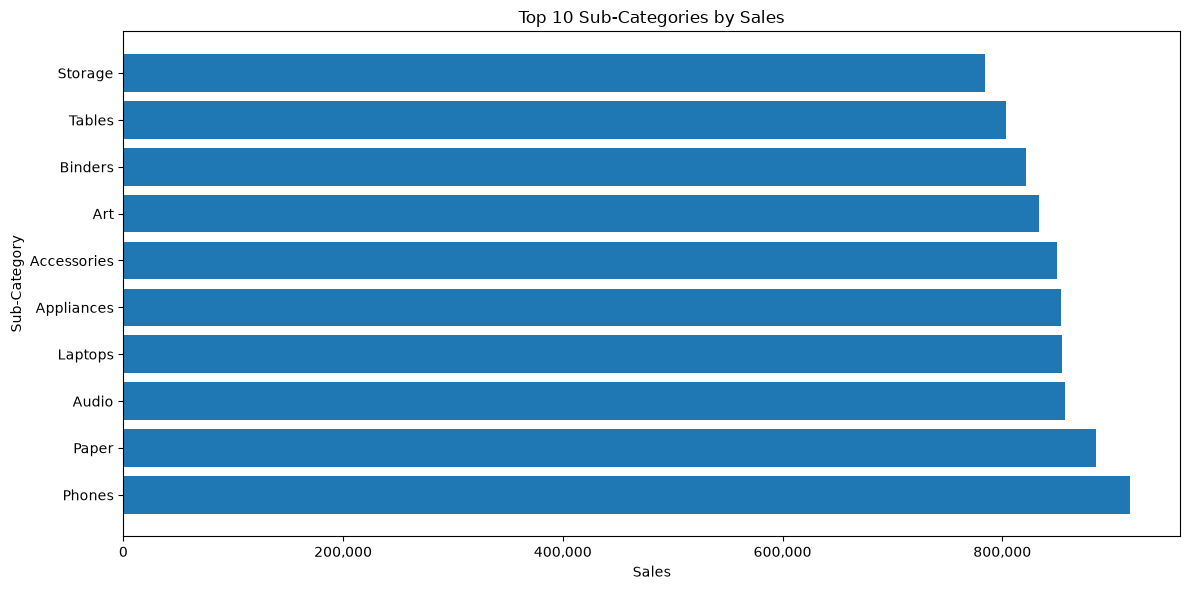

In [15]:
import matplotlib.ticker as ticker

Top_Subcategories_Sales = (
    Subcategory_Summary
    .sort_values("Total_Sales", ascending=False)
    .head(10)
)

plt.figure(figsize=(12, 6))

plt.barh(
    Top_Subcategories_Sales["Sub_Category"],
    Top_Subcategories_Sales["Total_Sales"]
)

plt.title("Top 10 Sub-Categories by Sales")
plt.xlabel("Sales")
plt.ylabel("Sub-Category")

plt.gca().xaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)

plt.tight_layout()
plt.show()

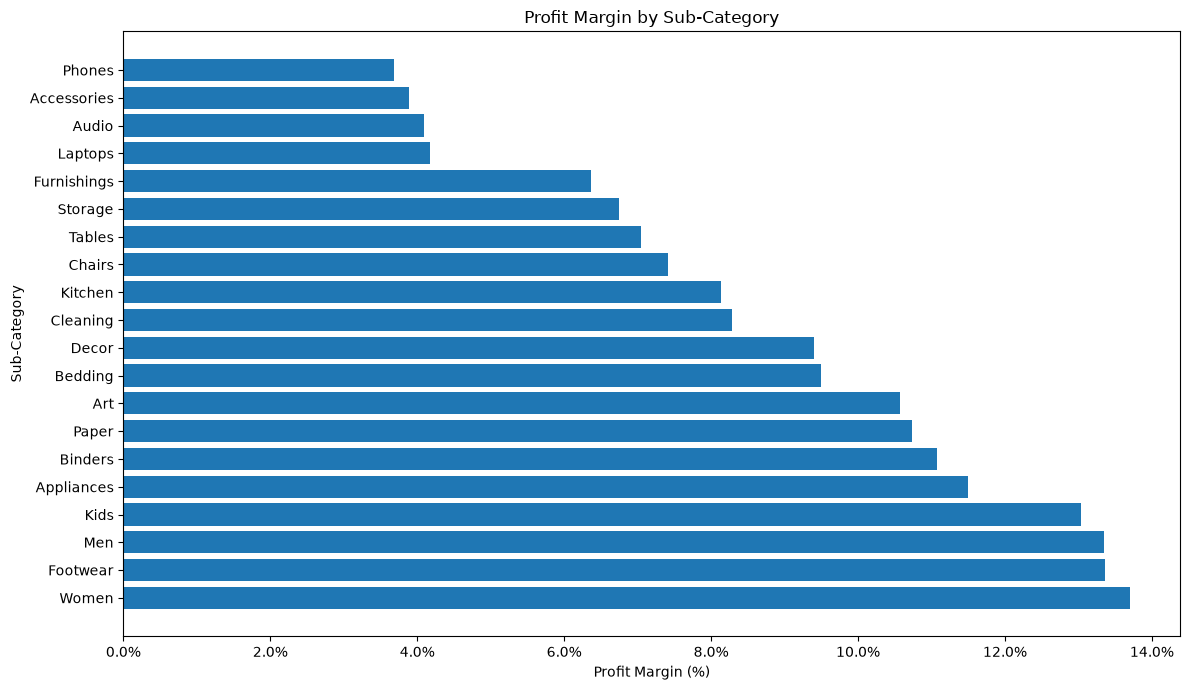

In [16]:
Margin_Subcategories = (
    Subcategory_Summary
    .sort_values("Profit_Margin_%", ascending=False)
)

plt.figure(figsize=(12, 7))

plt.barh(
    Margin_Subcategories["Sub_Category"],
    Margin_Subcategories["Profit_Margin_%"]
)

plt.title("Profit Margin by Sub-Category")
plt.xlabel("Profit Margin (%)")
plt.ylabel("Sub-Category")

plt.gca().xaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:.1f}%")
)

plt.tight_layout()
plt.show()

### Sub-Category Business Insights

* **Phone** generated the highest sales among the analyzed sub-categories.
* **Storage** generated the lowest sales.
* **Women** had the highest profit margin, while **Phone** had the lowest profit margin.
* Phone's position as the highest-sales but lowest-margin sub-category shows that high sales volume does not necessarily translate into high profitability.


### Business Action

Review pricing, discounting, and cost structure for Phone products to identify the factors behind its low margin despite strong sales. At the same time, investigate the practices and product characteristics contributing to Women's higher margin.


## 7. Regional Performance

### Business Question

How does business performance vary across regions, and which regions contribute the most to sales and profitability?


In [17]:
Portfolio_Region = (
    df.groupby("Region")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Orders=("Order_ID", "nunique"),
          Total_Customers=("Customer_ID", "nunique")
      )
      .reset_index()
)

Portfolio_Region["Profit_Margin_%"] = (
    Portfolio_Region["Total_Profit"]
    / Portfolio_Region["Total_Sales"]
) * 100

Portfolio_Region["AOV"] = (
    Portfolio_Region["Total_Sales"]
    / Portfolio_Region["Total_Orders"]
)

Portfolio_Region["Sales_Contribution_%"] = (
    Portfolio_Region["Total_Sales"]
    / Portfolio_Region["Total_Sales"].sum()
) * 100

Portfolio_Region["Profit_Contribution_%"] = (
    Portfolio_Region["Total_Profit"]
    / Portfolio_Region["Total_Profit"].sum()
) * 100

Portfolio_Region

,Region,Total_Sales,Total_Profit,Total_Orders,Total_Customers,Profit_Margin_%,AOV,Sales_Contribution_%,Profit_Contribution_%
0,East,3495628.59,299150.36,4562,2711,8.557842,766.249143,23.039884,23.070312
1,North,4172987.70,356592.39,5397,2957,8.545254,773.205058,27.504396,27.500210
2,South,3820952.40,327723.29,5056,2865,8.577005,755.726345,25.184111,25.273840
3,West,3682506.78,313223.68,4985,2783,8.505719,738.717509,24.271609,24.155638


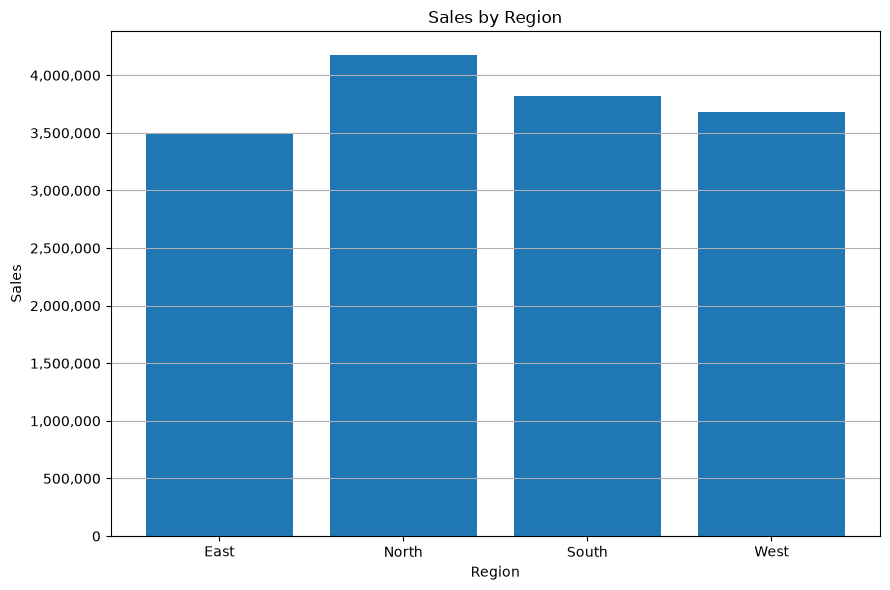

In [18]:
plt.figure(figsize=(9, 6))

plt.bar(
    Portfolio_Region["Region"],
    Portfolio_Region["Total_Sales"]
)

plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales")

plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)

plt.grid(axis="y")

plt.tight_layout()
plt.show()

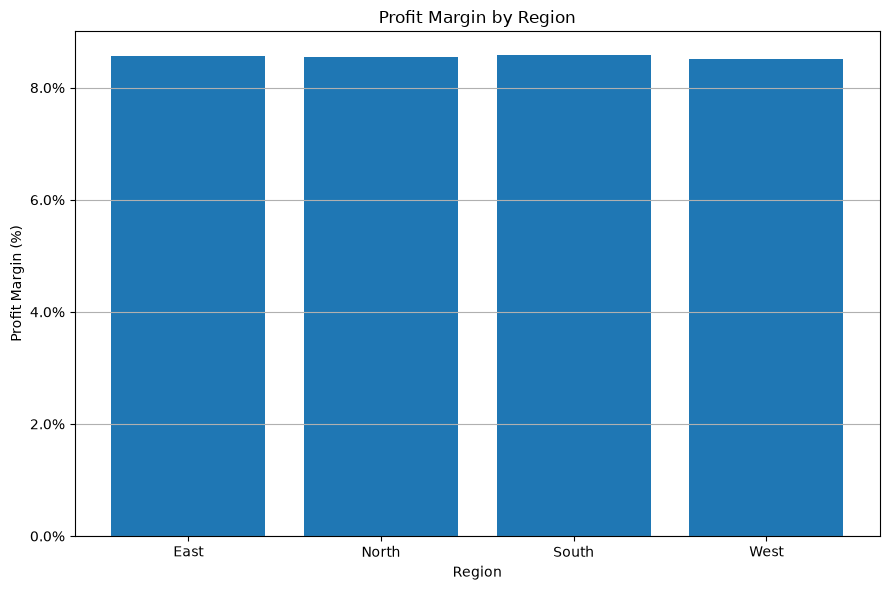

In [19]:
plt.figure(figsize=(9, 6))

plt.bar(
    Portfolio_Region["Region"],
    Portfolio_Region["Profit_Margin_%"]
)

plt.title("Profit Margin by Region")
plt.xlabel("Region")
plt.ylabel("Profit Margin (%)")

plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:.1f}%")
)

plt.grid(axis="y")

plt.tight_layout()
plt.show()

### Business Insights

* **North** generated the highest total sales among the regions, while **East** generated the lowest.
* Profit margins across **East, North, and South were relatively similar**.
* **West** had a slightly lower profit margin compared with the other regions.
* The regional analysis shows that sales contribution varies more noticeably across regions than profit margins.


### Business Action

Investigate the factors behind North's higher sales performance and evaluate opportunities to increase sales in East. Since regional profit margins are relatively close, improvement efforts should focus on sales growth and identifying the specific products, customers, and categories driving regional differences.


### Customer Analytics

**Business Question:**
Which customers contribute the most to sales and profit, and how concentrated is the business around high-value customers?

This analysis evaluates customer revenue, profitability, order frequency, and customer contribution to identify high-value customers and potential customer concentration risks.


In [20]:
Portfolio_Customer = (
    df.groupby("Customer_ID")
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Orders=("Order_ID", "nunique"),
          Total_Quantity=("Quantity", "sum")
      )
      .reset_index()
)

Portfolio_Customer["Profit_Margin_%"] = (
    Portfolio_Customer["Total_Profit"]
    / Portfolio_Customer["Total_Sales"]
) * 100

Portfolio_Customer["AOV"] = (
    Portfolio_Customer["Total_Sales"]
    / Portfolio_Customer["Total_Orders"]
)

Portfolio_Customer["Sales_Contribution_%"] = (
    Portfolio_Customer["Total_Sales"]
    / Portfolio_Customer["Total_Sales"].sum()
) * 100

Portfolio_Customer["Profit_Contribution_%"] = (
    Portfolio_Customer["Total_Profit"]
    / Portfolio_Customer["Total_Profit"].sum()
) * 100

Portfolio_Customer.head()

,Customer_ID,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Profit_Margin_%,AOV,Sales_Contribution_%,Profit_Contribution_%
0,1001,3017.07,51.63,6,27.0,1.711263,502.845000,0.019886,0.003982
1,1002,2468.87,279.75,6,20.0,11.331095,411.478333,0.016272,0.021574
2,1003,438.77,15.19,2,5.0,3.461950,219.385000,0.002892,0.001171
3,1004,4544.00,264.16,9,27.0,5.813380,504.888889,0.029950,0.020372
4,1005,3736.61,560.61,6,21.0,15.003171,622.768333,0.024628,0.043234


In [21]:
Top_Customers_Sales = (
    Portfolio_Customer
    .sort_values("Total_Sales", ascending=False)
    .head(10)
)

display(
    Top_Customers_Sales.style.format({
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Profit_Margin_%": "{:.2f}%",
        "AOV": "₹{:,.2f}",
        "Sales_Contribution_%": "{:.2f}%",
        "Profit_Contribution_%": "{:.2f}%"
    })
)

,Customer_ID,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Profit_Margin_%,AOV,Sales_Contribution_%,Profit_Contribution_%
379,1381,"₹25,367.09","₹3,030.05",5,26.000000,11.94%,"₹5,073.42",0.17%,0.23%
668,1671,"₹25,201.17",₹900.76,10,44.000000,3.57%,"₹2,520.12",0.17%,0.07%
2407,3419,"₹22,288.86","₹3,198.16",13,52.000000,14.35%,"₹1,714.53",0.15%,0.25%
2781,3793,"₹21,432.28","₹2,300.47",9,51.000000,10.73%,"₹2,381.36",0.14%,0.18%
3780,4796,"₹20,174.14","₹1,504.18",9,42.000000,7.46%,"₹2,241.57",0.13%,0.12%
815,1819,"₹17,902.80","₹1,619.49",11,40.000000,9.05%,"₹1,627.53",0.12%,0.12%
3457,4473,"₹17,620.58",₹986.93,6,27.000000,5.60%,"₹2,936.76",0.12%,0.08%
2353,3365,"₹17,375.92","₹1,961.16",8,25.000000,11.29%,"₹2,171.99",0.11%,0.15%
1134,2139,"₹17,190.17","₹1,398.89",10,47.000000,8.14%,"₹1,719.02",0.11%,0.11%
187,1188,"₹16,899.50","₹1,367.73",9,41.000000,8.09%,"₹1,877.72",0.11%,0.11%


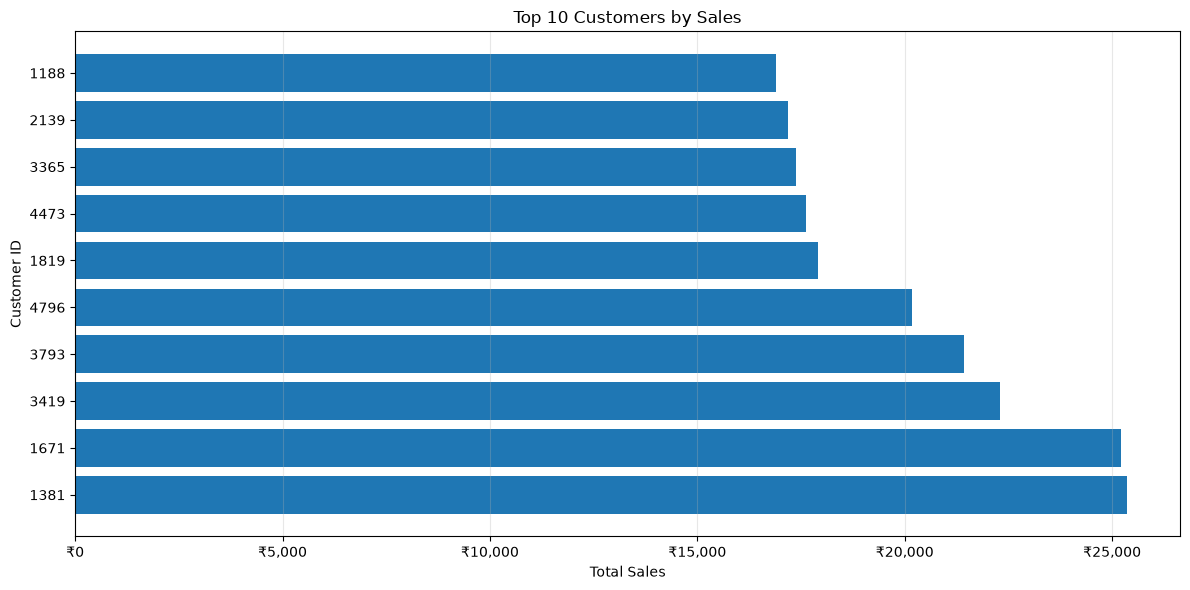

In [22]:
plt.figure(figsize=(12, 6))

plt.barh(
    Top_Customers_Sales["Customer_ID"].astype(str),
    Top_Customers_Sales["Total_Sales"]
)

plt.title("Top 10 Customers by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Customer ID")

plt.gca().xaxis.set_major_formatter(
    ticker.StrMethodFormatter("₹{x:,.0f}")
)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Insight:**
Customer 1381 generated the highest sales at ₹25,367.09. The top 5 customers each generated more than ₹20K in sales, with sales ranging from approximately ₹20.17K to ₹25.37K. This indicates that sales among the highest-value customers are relatively distributed rather than being dominated by a single customer.

**Business Action:**
Maintain strong relationships with these high-value customers through retention strategies, personalized offers, and targeted engagement to protect valuable revenue.


In [23]:
Top_Customers_Profit = (
    Portfolio_Customer
    .sort_values("Total_Profit", ascending=False)
    .head(10)
)

display(
    Top_Customers_Profit.style.format({
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Profit_Margin_%": "{:.2f}%",
        "AOV": "₹{:,.2f}",
        "Sales_Contribution_%": "{:.2f}%",
        "Profit_Contribution_%": "{:.2f}%"
    })
)

,Customer_ID,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Profit_Margin_%,AOV,Sales_Contribution_%,Profit_Contribution_%
2407,3419,"₹22,288.86","₹3,198.16",13,52.000000,14.35%,"₹1,714.53",0.15%,0.25%
3403,4418,"₹16,698.37","₹3,124.36",4,9.000000,18.71%,"₹4,174.59",0.11%,0.24%
379,1381,"₹25,367.09","₹3,030.05",5,26.000000,11.94%,"₹5,073.42",0.17%,0.23%
3290,4305,"₹16,800.22","₹2,990.29",4,16.000000,17.80%,"₹4,200.06",0.11%,0.23%
3670,4686,"₹13,176.59","₹2,789.32",8,23.000000,21.17%,"₹1,647.07",0.09%,0.22%
2593,3605,"₹16,364.20","₹2,759.01",7,30.000000,16.86%,"₹2,337.74",0.11%,0.21%
3866,4882,"₹14,721.90","₹2,704.10",8,26.000000,18.37%,"₹1,840.24",0.10%,0.21%
2949,3963,"₹15,816.67","₹2,696.42",6,22.000000,17.05%,"₹2,636.11",0.10%,0.21%
2781,3793,"₹21,432.28","₹2,300.47",9,51.000000,10.73%,"₹2,381.36",0.14%,0.18%
1460,2467,"₹14,092.84","₹2,243.10",8,51.000000,15.92%,"₹1,761.61",0.09%,0.17%


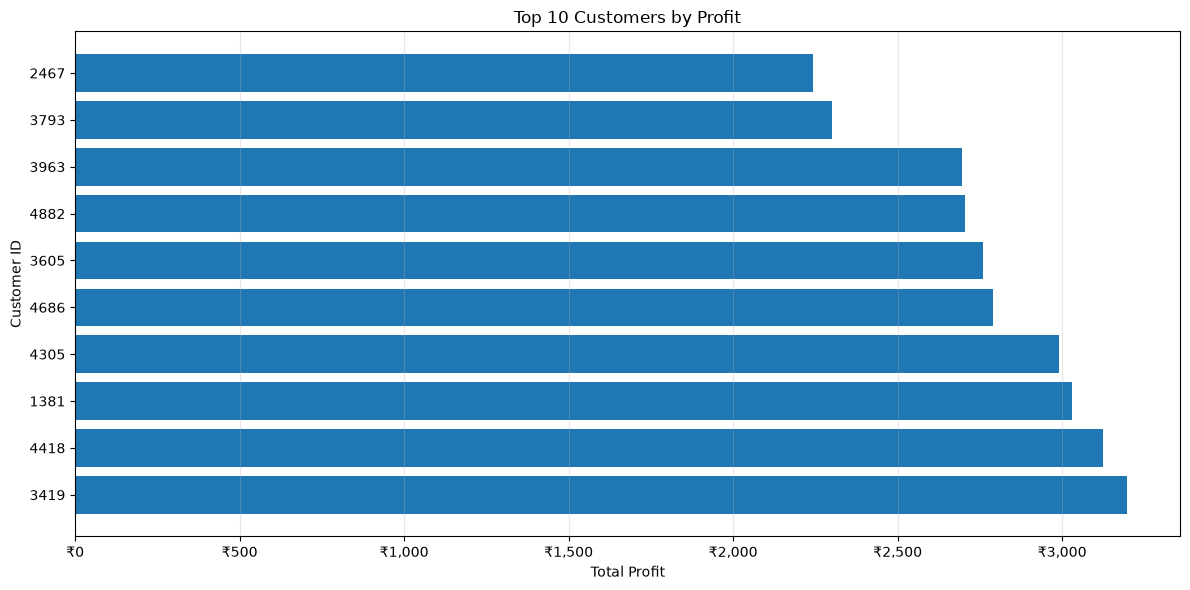

In [24]:
plt.figure(figsize=(12, 6))

plt.barh(
    Top_Customers_Profit["Customer_ID"].astype(str),
    Top_Customers_Profit["Total_Profit"]
)

plt.title("Top 10 Customers by Profit")
plt.xlabel("Total Profit")
plt.ylabel("Customer ID")

plt.gca().xaxis.set_major_formatter(
    ticker.StrMethodFormatter("₹{x:,.0f}")
)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Insight:**
Customer 3419 generated the highest total profit at ₹3,198.16. The customers generating the highest profit are not the same as the customers generating the highest sales, indicating that customer revenue and profitability do not always move together.

**Business Action:**
Evaluate high-value customers using both sales and profit rather than sales alone. Prioritize customers who generate sustainable profit and review pricing, discounts, and product mix for high-sales but lower-profit customers.


In [25]:
One_Time_Customers = (Portfolio_Customer["Total_Orders"] == 1).sum()
Repeat_Customers = (Portfolio_Customer["Total_Orders"] > 1).sum()

Customer_Type_Summary = pd.DataFrame({
    "Customer_Type": ["One-Time", "Repeat"],
    "Customers": [One_Time_Customers, Repeat_Customers]
})

Customer_Type_Summary["Percentage_%"] = (
    Customer_Type_Summary["Customers"]
    / Customer_Type_Summary["Customers"].sum()
) * 100

display(
    Customer_Type_Summary.style.format({
        "Percentage_%": "{:.2f}%"
    })
)

,Customer_Type,Customers,Percentage_%
0,One-Time,149,3.74%
1,Repeat,3833,96.26%


**Insight:**
The customer base is strongly repeat-oriented, with 3,833 customers (96.26%) making more than one purchase, while only 149 customers (3.74%) purchased once. This indicates that repeat purchasing represents the dominant customer behavior in the dataset.

**Business Action:**
Maintain retention-focused strategies for repeat customers while investigating the reasons behind one-time purchases to identify opportunities for converting them into repeat customers.



In [26]:
Top_10_Count = int(len(Portfolio_Customer) * 0.10)

Top_10_Customers = (
    Portfolio_Customer
    .sort_values("Total_Sales", ascending=False)
    .head(Top_10_Count)
)

Top_10_Sales = Top_10_Customers["Total_Sales"].sum()

Total_Customer_Sales = Portfolio_Customer["Total_Sales"].sum()

Top_10_Sales_Contribution = (
    Top_10_Sales / Total_Customer_Sales
) * 100

Customer_Concentration = pd.DataFrame({
    "Metric": [
        "Total Customers",
        "Top 10% Customer Count",
        "Top 10% Customer Sales",
        "Top 10% Sales Contribution"
    ],
    "Value": [
        len(Portfolio_Customer),
        Top_10_Count,
        Top_10_Sales,
        Top_10_Sales_Contribution
    ]
})

display(
    Customer_Concentration.style.format({
        "Value": lambda x: f"{x:,.2f}"
    })
)

,Metric,Value
0,Total Customers,"3,982.00"
1,Top 10% Customer Count,398.00
2,Top 10% Customer Sales,"3,922,982.88"
3,Top 10% Sales Contribution,25.86


**Insight:**
The top 10% of customers (398 out of 3,982) generated ₹39.23 lakh in sales, contributing 25.86% of total sales. This shows that a relatively small segment of customers contributes a substantial share of overall revenue.

**Business Action:**
Maintain strong engagement with high-value customers through retention and personalized strategies, while continuing to develop the broader customer base to avoid excessive dependence on a small customer segment.


In [27]:
Avg_Customer_Sales = Portfolio_Customer["Total_Sales"].mean()

High_Sales_Low_Margin = (
    Portfolio_Customer[
        (Portfolio_Customer["Total_Sales"] > Avg_Customer_Sales) &
        (Portfolio_Customer["Profit_Margin_%"] < 5)
    ]
    .sort_values("Total_Sales", ascending=False)
)

display(
    High_Sales_Low_Margin.style.format({
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Profit_Margin_%": "{:.2f}%",
        "AOV": "₹{:,.2f}",
        "Sales_Contribution_%": "{:.2f}%",
        "Profit_Contribution_%": "{:.2f}%"
    })
)

,Customer_ID,Total_Sales,Total_Profit,Total_Orders,Total_Quantity,Profit_Margin_%,AOV,Sales_Contribution_%,Profit_Contribution_%
668,1671,"₹25,201.17",₹900.76,10,44.000000,3.57%,"₹2,520.12",0.17%,0.07%
1747,2757,"₹15,103.71","₹-1,066.61",6,24.000000,-7.06%,"₹2,517.28",0.10%,-0.08%
2413,3425,"₹14,825.90",₹-125.80,10,35.000000,-0.85%,"₹1,482.59",0.10%,-0.01%
2653,3665,"₹14,558.54",₹295.83,7,33.000000,2.03%,"₹2,079.79",0.10%,0.02%
1227,2234,"₹13,915.43",₹-946.98,4,22.000000,-6.81%,"₹3,478.86",0.09%,-0.07%
1336,2343,"₹13,906.35",₹303.75,8,33.000000,2.18%,"₹1,738.29",0.09%,0.02%
2321,3333,"₹13,868.23",₹436.21,7,30.000000,3.15%,"₹1,981.18",0.09%,0.03%
498,1500,"₹13,609.10",₹-521.05,10,37.000000,-3.83%,"₹1,360.91",0.09%,-0.04%
3279,4294,"₹12,674.97",₹421.45,11,46.000000,3.33%,"₹1,152.27",0.08%,0.03%
1827,2837,"₹12,108.69",₹217.50,8,37.000000,1.80%,"₹1,513.59",0.08%,0.02%


In [28]:
High_Sales_Low_Margin_Summary = pd.DataFrame({
    "Metric": [
        "Customers",
        "Total Sales",
        "Total Profit",
        "Average Profit Margin"
    ],
    "Value": [
        len(High_Sales_Low_Margin),
        High_Sales_Low_Margin["Total_Sales"].sum(),
        High_Sales_Low_Margin["Total_Profit"].sum(),
        High_Sales_Low_Margin["Profit_Margin_%"].mean()
    ]
})

display(
    High_Sales_Low_Margin_Summary.style.format({
        "Value": "{:,.2f}"
    })
)

,Metric,Value
0,Customers,334.00
1,Total Sales,"2,107,498.78"
2,Total Profit,"38,566.56"
3,Average Profit Margin,1.97


**Insight:** 334 customers generate above-average sales but have a profit margin below 5%. Together, they generated ₹21.07 lakh in sales but only ₹38,566.56 in profit, with an average profit margin of 1.97%. This indicates that a significant group of high-sales customers contributes relatively low profitability.

**Business Action:** Review pricing, discount levels, product mix, and cost-to-serve for these customers. Focus on improving margin without unnecessarily reducing sales volume.


In [29]:
Customer_Profitability = Portfolio_Customer.copy()

Customer_Profitability["Profitability_Segment"] = np.select(
    [
        Customer_Profitability["Profit_Margin_%"] >= 15,
        Customer_Profitability["Profit_Margin_%"] >= 5,
        Customer_Profitability["Profit_Margin_%"] >= 0
    ],
    [
        "High Margin",
        "Medium Margin",
        "Low Margin"
    ],
    default="Loss"
)

Customer_Profitability_Summary = (
    Customer_Profitability
    .groupby("Profitability_Segment")
    .agg(
        Customers=("Customer_ID", "count"),
        Total_Sales=("Total_Sales", "sum"),
        Total_Profit=("Total_Profit", "sum")
    )
    .reset_index()
)

Customer_Profitability_Summary["Customer_%"] = (
    Customer_Profitability_Summary["Customers"]
    / Customer_Profitability_Summary["Customers"].sum()
) * 100

display(
    Customer_Profitability_Summary.style.format({
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Customer_%": "{:.2f}%"
    })
)

,Profitability_Segment,Customers,Total_Sales,Total_Profit,Customer_%
0,High Margin,390,"₹1,409,800.61","₹243,446.55",9.79%
1,Loss,235,"₹729,924.75","₹-18,808.69",5.90%
2,Low Margin,684,"₹2,539,972.78","₹75,610.69",17.18%
3,Medium Margin,2673,"₹10,492,377.33","₹996,441.17",67.13%


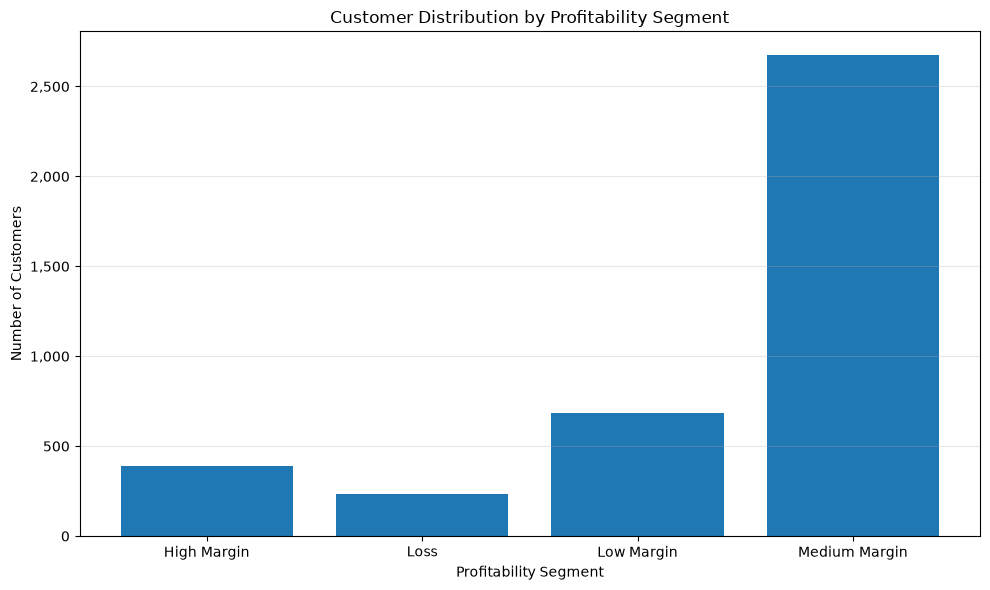

In [30]:
plt.figure(figsize=(10, 6))

plt.bar(
    Customer_Profitability_Summary["Profitability_Segment"],
    Customer_Profitability_Summary["Customers"]
)

plt.title("Customer Distribution by Profitability Segment")
plt.xlabel("Profitability Segment")
plt.ylabel("Number of Customers")

plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:,.0f}")
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

**Insight:** Most customers (67.13%) fall into the Medium Margin segment and generate the majority of total customer sales and profit. However, 684 customers (17.18%) are in the Low Margin segment, while 235 customers (5.90%) generate losses. Together, these 919 customers represent 23.08% of the customer base and include substantial sales with relatively weak or negative profitability.

**Business Action:** Prioritize profitability improvement for Low Margin and Loss customers by reviewing pricing, discounts, product mix, and cost-to-serve. At the same time, maintain the High Margin customer segment through targeted retention strategies.


In [31]:
Customer_Frequency = (
    Portfolio_Customer
    .groupby("Total_Orders")
    .agg(
        Customers=("Customer_ID", "count"),
        Total_Sales=("Total_Sales", "sum"),
        Total_Profit=("Total_Profit", "sum")
    )
    .reset_index()
)

Customer_Frequency["Average_Sales_Per_Customer"] = (
    Customer_Frequency["Total_Sales"]
    / Customer_Frequency["Customers"]
)

Customer_Frequency["Average_Profit_Per_Customer"] = (
    Customer_Frequency["Total_Profit"]
    / Customer_Frequency["Customers"]
)

display(
    Customer_Frequency.style.format({
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Average_Sales_Per_Customer": "₹{:,.2f}",
        "Average_Profit_Per_Customer": "₹{:,.2f}"
    })
)

,Total_Orders,Customers,Total_Sales,Total_Profit,Average_Sales_Per_Customer,Average_Profit_Per_Customer
0,1,149,"₹102,794.43","₹7,915.64",₹689.90,₹53.13
1,2,346,"₹535,225.22","₹45,732.99","₹1,546.89",₹132.18
2,3,548,"₹1,193,163.70","₹99,849.22","₹2,177.31",₹182.21
3,4,712,"₹2,189,166.17","₹188,542.55","₹3,074.67",₹264.81
4,5,699,"₹2,607,614.92","₹220,070.62","₹3,730.49",₹314.84
5,6,588,"₹2,601,952.14","₹228,044.45","₹4,425.09",₹387.83
6,7,405,"₹2,158,717.51","₹181,504.57","₹5,330.17",₹448.16
7,8,252,"₹1,607,057.38","₹144,041.68","₹6,377.21",₹571.59
8,9,150,"₹1,008,041.99","₹82,879.60","₹6,720.28",₹552.53
9,10,65,"₹536,454.71","₹44,387.17","₹8,253.15",₹682.88


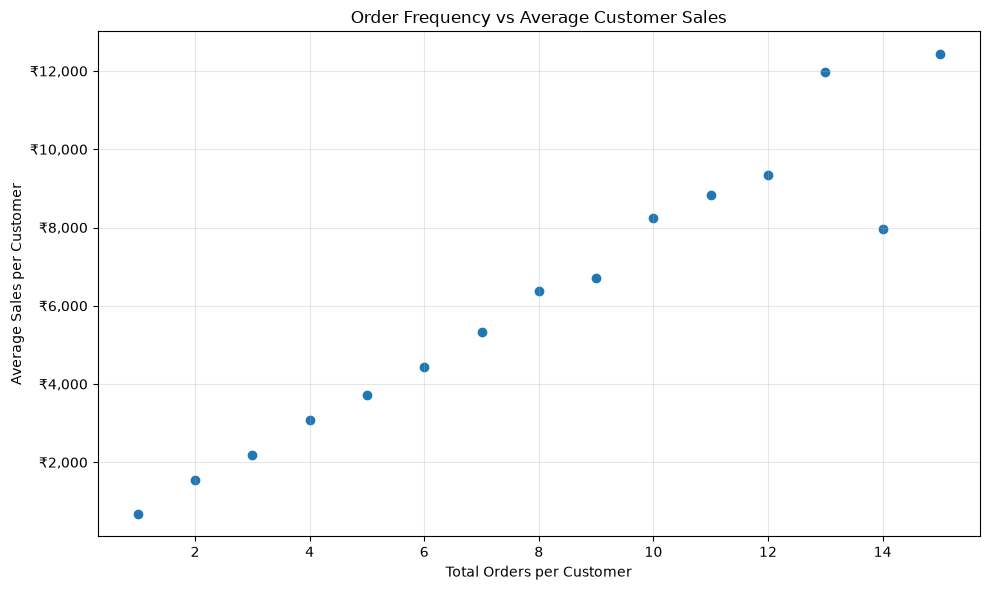

In [32]:
plt.figure(figsize=(10, 6))

plt.scatter(
    Customer_Frequency["Total_Orders"],
    Customer_Frequency["Average_Sales_Per_Customer"]
)

plt.title("Order Frequency vs Average Customer Sales")
plt.xlabel("Total Orders per Customer")
plt.ylabel("Average Sales per Customer")

plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter("₹{x:,.0f}")
)

plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Insight:** Average customer sales generally increase as order frequency increases. Customers with one order generated an average of ₹689.90 in sales, while customers with 10 orders generated ₹8,253.15 on average. This indicates that more frequent customers tend to have higher customer value, although the highest-frequency groups contain very few customers.

**Business Action:** Focus retention and repeat-purchase strategies on increasing customer order frequency. Encourage existing customers to make additional purchases through personalized recommendations, relevant offers, and re-engagement campaigns.


In [33]:
Portfolio_Product = (
    df.groupby(["Product_Name", "Category", "Sub_Category"])
      .agg(
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Quantity=("Quantity", "sum"),
          Total_Orders=("Order_ID", "nunique")
      )
      .reset_index()
)

Portfolio_Product["Profit_Margin_%"] = (
    Portfolio_Product["Total_Profit"]
    / Portfolio_Product["Total_Sales"]
) * 100

Portfolio_Product["Sales_Contribution_%"] = (
    Portfolio_Product["Total_Sales"]
    / Portfolio_Product["Total_Sales"].sum()
) * 100

Portfolio_Product["Profit_Contribution_%"] = (
    Portfolio_Product["Total_Profit"]
    / Portfolio_Product["Total_Profit"].sum()
) * 100

In [34]:
Top_Products_Sales = (
    Portfolio_Product
    .sort_values("Total_Sales", ascending=False)
    .head(10)
)

display(
    Top_Products_Sales.style.format({
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Total_Quantity": "{:,.0f}",
        "Profit_Margin_%": "{:.2f}%",
        "Sales_Contribution_%": "{:.2f}%",
        "Profit_Contribution_%": "{:.2f}%"
    })
)

,Product_Name,Category,Sub_Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin_%,Sales_Contribution_%,Profit_Contribution_%
69,USB Hub,Electronics,Accessories,"₹237,444.78","₹6,445.21",988,316,2.71%,1.57%,0.50%
59,Sketch Pens,Office Supplies,Art,"₹235,621.72","₹26,467.07",968,305,11.23%,1.55%,2.04%
29,Headphones,Electronics,Audio,"₹235,036.57","₹10,015.17","1,008",304,4.26%,1.55%,0.77%
61,Smartphone X,Electronics,Phones,"₹235,002.10","₹8,827.01",955,302,3.76%,1.55%,0.68%
44,Notebook,Office Supplies,Paper,"₹233,883.17","₹23,347.16","1,023",308,9.98%,1.54%,1.80%
58,Shredder,Office Supplies,Appliances,"₹233,553.18","₹27,882.74",949,293,11.94%,1.54%,2.15%
0,5G Phone,Electronics,Phones,"₹231,882.36","₹7,406.69",954,307,3.19%,1.53%,0.57%
66,Student Laptop,Electronics,Laptops,"₹231,685.57","₹8,516.07",927,293,3.68%,1.53%,0.66%
60,Smartphone Pro,Electronics,Phones,"₹230,003.74","₹8,801.25",971,303,3.83%,1.52%,0.68%
35,Lamp,Furniture,Furnishings,"₹226,303.81","₹15,708.53",957,276,6.94%,1.49%,1.21%


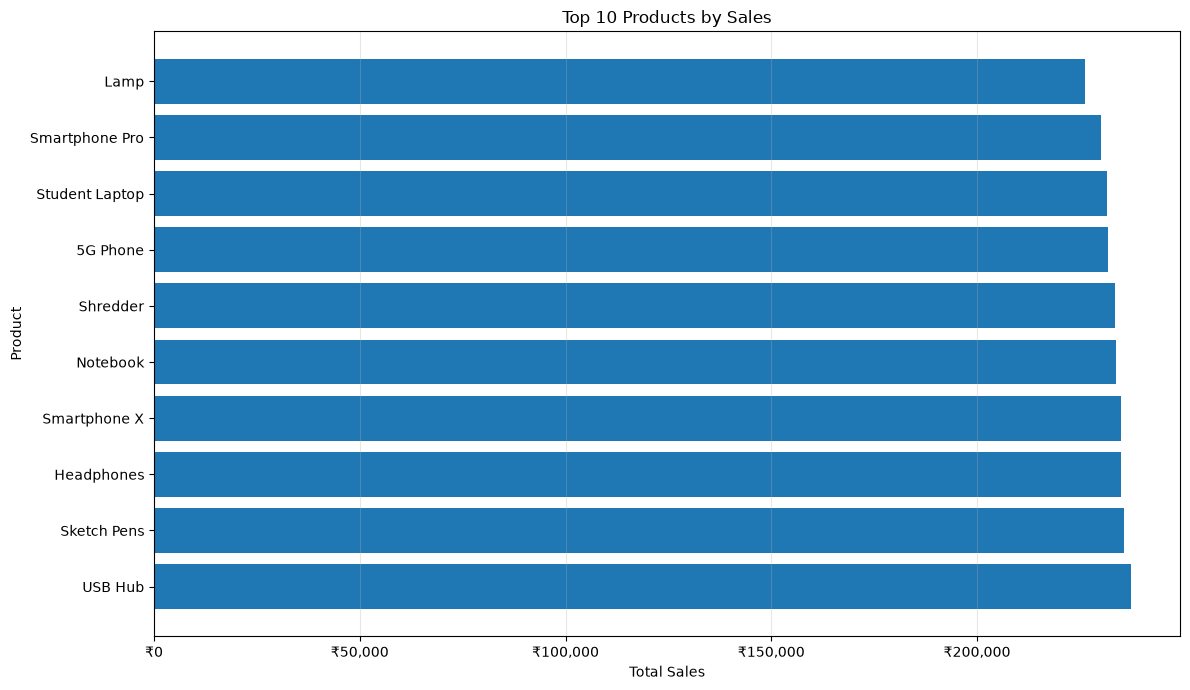

In [35]:
plt.figure(figsize=(12, 7))

plt.barh(
    Top_Products_Sales["Product_Name"],
    Top_Products_Sales["Total_Sales"]
)

plt.title("Top 10 Products by Sales")
plt.xlabel("Total Sales")
plt.ylabel("Product")

plt.gca().xaxis.set_major_formatter(
    ticker.StrMethodFormatter("₹{x:,.0f}")
)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Insight:** The highest-selling products generate similar sales volumes, but their profitability varies considerably. For example, USB Hub generated ₹2.37 lakh in sales with a 2.71% profit margin, while Shredder generated ₹2.34 lakh in sales with an 11.94% margin. This shows that high product sales do not necessarily translate into high profitability.

**Business Action:** Review pricing, discounting, product costs, and product mix for high-sales products with low margins. Protect and potentially expand products that combine strong sales with healthier margins.


In [36]:
Top_Products_Profit = (
    Portfolio_Product
    .sort_values("Total_Profit", ascending=False)
    .head(10)
)

display(
    Top_Products_Profit.style.format({
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Total_Quantity": "{:,.0f}",
        "Profit_Margin_%": "{:.2f}%",
        "Sales_Contribution_%": "{:.2f}%",
        "Profit_Contribution_%": "{:.2f}%"
    })
)

,Product_Name,Category,Sub_Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin_%,Sales_Contribution_%,Profit_Contribution_%
24,File Folder,Office Supplies,Binders,"₹225,353.79","₹28,363.29",931,273,12.59%,1.49%,2.19%
58,Shredder,Office Supplies,Appliances,"₹233,553.18","₹27,882.74",949,293,11.94%,1.54%,2.15%
59,Sketch Pens,Office Supplies,Art,"₹235,621.72","₹26,467.07",968,305,11.23%,1.55%,2.04%
76,Women Dress,Clothing,Women,"₹172,249.20","₹25,293.74",696,216,14.68%,1.14%,1.95%
9,Calculator,Office Supplies,Appliances,"₹214,129.85","₹24,602.21",942,286,11.49%,1.41%,1.90%
63,Sticky Notes,Office Supplies,Paper,"₹208,394.88","₹24,331.47",866,264,11.68%,1.37%,1.88%
14,Copy Paper,Office Supplies,Paper,"₹223,696.51","₹23,751.28",927,282,10.62%,1.47%,1.83%
40,Men Shirt,Clothing,Men,"₹181,250.03","₹23,721.06",643,210,13.09%,1.19%,1.83%
53,Printer Paper,Office Supplies,Paper,"₹219,718.96","₹23,679.35",880,279,10.78%,1.45%,1.83%
56,Running Shoes,Clothing,Footwear,"₹172,999.06","₹23,458.95",655,225,13.56%,1.14%,1.81%


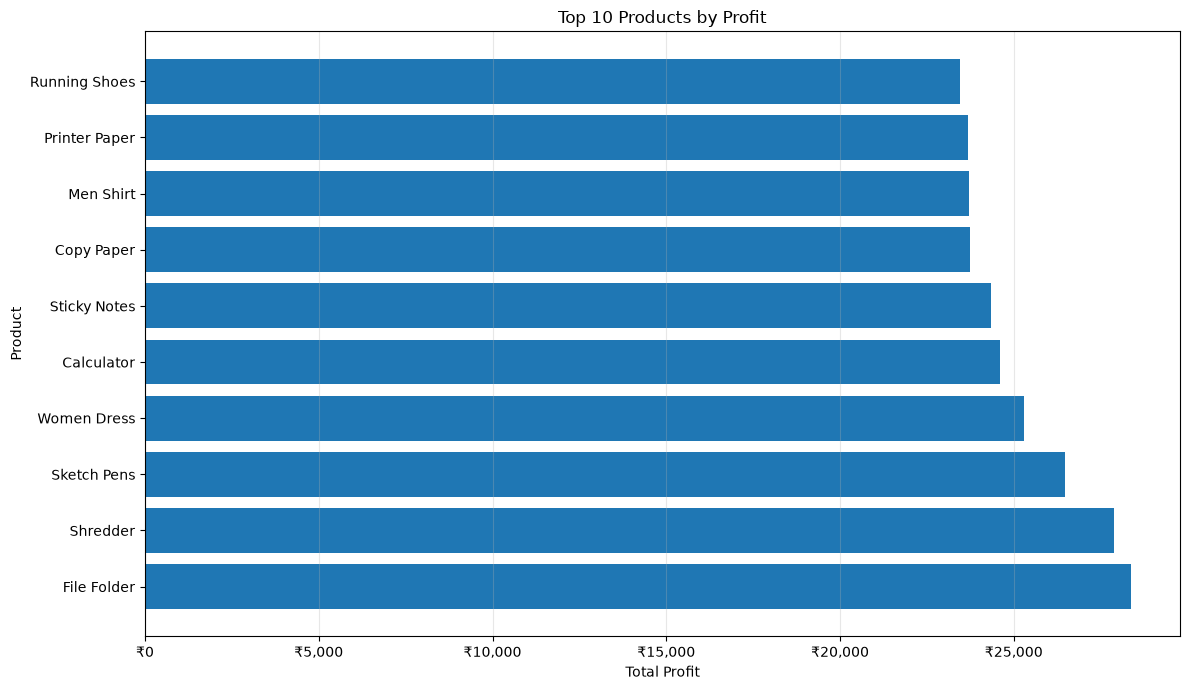

In [37]:
plt.figure(figsize=(12, 7))

plt.barh(
    Top_Products_Profit["Product_Name"],
    Top_Products_Profit["Total_Profit"]
)

plt.title("Top 10 Products by Profit")
plt.xlabel("Total Profit")
plt.ylabel("Product")

plt.gca().xaxis.set_major_formatter(
    ticker.StrMethodFormatter("₹{x:,.0f}")
)

plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

**Insight:** The highest-profit products are not necessarily the highest-selling products. File Folder generated the highest total profit of ₹28,363.29 despite not appearing in the Top 10 products by sales. Shredder and Sketch Pens performed strongly in both sales and profit, while Women Dress achieved the highest profit margin among the top-profit products at 14.68%. Overall, the top-profit products show healthier margins than several high-sales products, indicating that sales volume alone does not determine product profitability.

**Business Action:** Prioritize products that combine strong sales with healthy profit margins. Review pricing, discounting, and cost structures for high-sales products with comparatively low margins, while identifying the characteristics of high-margin products that could be applied to other product lines.


In [38]:
Avg_Product_Sales = Portfolio_Product["Total_Sales"].mean()

High_Sales_Low_Margin_Products = (
    Portfolio_Product[
        (Portfolio_Product["Total_Sales"] > Avg_Product_Sales) &
        (Portfolio_Product["Profit_Margin_%"] < 5)
    ]
    .sort_values("Total_Sales", ascending=False)
)

display(
    High_Sales_Low_Margin_Products.style.format({
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Total_Quantity": "{:,.0f}",
        "Total_Orders": "{:,.0f}",
        "Profit_Margin_%": "{:.2f}%",
        "Sales_Contribution_%": "{:.2f}%",
        "Profit_Contribution_%": "{:.2f}%"
    })
)

,Product_Name,Category,Sub_Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin_%,Sales_Contribution_%,Profit_Contribution_%
69,USB Hub,Electronics,Accessories,"₹237,444.78","₹6,445.21",988,316,2.71%,1.57%,0.50%
29,Headphones,Electronics,Audio,"₹235,036.57","₹10,015.17","1,008",304,4.26%,1.55%,0.77%
61,Smartphone X,Electronics,Phones,"₹235,002.10","₹8,827.01",955,302,3.76%,1.55%,0.68%
0,5G Phone,Electronics,Phones,"₹231,882.36","₹7,406.69",954,307,3.19%,1.53%,0.57%
66,Student Laptop,Electronics,Laptops,"₹231,685.57","₹8,516.07",927,293,3.68%,1.53%,0.66%
60,Smartphone Pro,Electronics,Phones,"₹230,003.74","₹8,801.25",971,303,3.83%,1.52%,0.68%
4,Bluetooth Speaker,Electronics,Audio,"₹221,114.63","₹7,213.18",925,285,3.26%,1.46%,0.56%
7,Budget Phone,Electronics,Phones,"₹219,088.33","₹8,761.38",944,304,4.00%,1.44%,0.68%
70,Ultrabook,Electronics,Laptops,"₹218,638.40","₹10,714.80",913,299,4.90%,1.44%,0.83%
62,Soundbar,Electronics,Audio,"₹212,867.64","₹8,588.83",828,260,4.03%,1.40%,0.66%


In [39]:
High_Sales_Low_Margin_Product_Summary = pd.DataFrame({
    "Metric": [
        "Products",
        "Total Sales",
        "Total Profit",
        "Average Profit Margin"
    ],
    "Value": [
        len(High_Sales_Low_Margin_Products),
        High_Sales_Low_Margin_Products["Total_Sales"].sum(),
        High_Sales_Low_Margin_Products["Total_Profit"].sum(),
        High_Sales_Low_Margin_Products["Profit_Margin_%"].mean()
    ]
})

display(
    High_Sales_Low_Margin_Product_Summary.style.format({
        "Value": lambda x: f"{x:,.2f}"
    })
)

,Metric,Value
0,Products,14.00
1,Total Sales,"3,087,173.49"
2,Total Profit,"117,371.18"
3,Average Profit Margin,3.81


**Insight:** 14 products generate above-average sales while maintaining profit margins below 5%. Together, these products generate approximately ₹30.87 lakh in sales but only ₹1.17 lakh in profit, resulting in an overall margin of approximately 3.80%. All 14 products belong to the Electronics category, indicating that Electronics contains several high-volume products with relatively weak profitability.

**Business Action:** Review pricing, discount levels, product costs, and supplier margins across the affected Electronics products. Products with strong sales volume should be evaluated for margin improvement opportunities without unnecessarily reducing demand. Particular attention should be given to products with margins close to or below 3%.


In [40]:
Low_Sales_High_Margin_Products = (
    Portfolio_Product[
        (Portfolio_Product["Total_Sales"] < Avg_Product_Sales) &
        (Portfolio_Product["Profit_Margin_%"] >= 10)
    ]
    .sort_values("Profit_Margin_%", ascending=False)
)

display(
    Low_Sales_High_Margin_Products.style.format({
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Total_Quantity": "{:,.0f}",
        "Total_Orders": "{:,.0f}",
        "Profit_Margin_%": "{:.2f}%",
        "Sales_Contribution_%": "{:.2f}%",
        "Profit_Contribution_%": "{:.2f}%"
    })
)

,Product_Name,Category,Sub_Category,Total_Sales,Total_Profit,Total_Quantity,Total_Orders,Profit_Margin_%,Sales_Contribution_%,Profit_Contribution_%
76,Women Dress,Clothing,Women,"₹172,249.20","₹25,293.74",696,216,14.68%,1.14%,1.95%
77,Women Jacket,Clothing,Women,"₹158,485.53","₹22,456.78",627,198,14.17%,1.04%,1.73%
57,Sandals,Clothing,Footwear,"₹140,660.04","₹19,634.69",584,177,13.96%,0.93%,1.51%
34,Kids T-Shirt,Clothing,Kids,"₹157,816.04","₹21,927.15",646,213,13.89%,1.04%,1.69%
78,Women Jeans,Clothing,Women,"₹165,566.86","₹22,904.88",689,213,13.83%,1.09%,1.77%
39,Men Jeans,Clothing,Men,"₹149,383.97","₹20,519.85",639,207,13.74%,0.98%,1.58%
56,Running Shoes,Clothing,Footwear,"₹172,999.06","₹23,458.95",655,225,13.56%,1.14%,1.81%
38,Men Jacket,Clothing,Men,"₹171,530.47","₹23,002.60",739,218,13.41%,1.13%,1.77%
33,Kids Shoes,Clothing,Kids,"₹128,339.68","₹17,019.85",544,188,13.26%,0.85%,1.31%
41,Men T-Shirt,Clothing,Men,"₹132,720.52","₹17,476.99",603,195,13.17%,0.87%,1.35%


In [41]:
Low_Sales_High_Margin_Summary = pd.DataFrame({
    "Metric": [
        "Products",
        "Total Sales",
        "Total Profit",
        "Average Profit Margin"
    ],
    "Value": [
        len(Low_Sales_High_Margin_Products),
        Low_Sales_High_Margin_Products["Total_Sales"].sum(),
        Low_Sales_High_Margin_Products["Total_Profit"].sum(),
        Low_Sales_High_Margin_Products["Profit_Margin_%"].mean()
    ]
})

display(
    Low_Sales_High_Margin_Summary.style.format({
        "Value": lambda x: f"{x:,.2f}"
    })
)

,Metric,Value
0,Products,18.00
1,Total Sales,"2,855,297.71"
2,Total Profit,"372,922.45"
3,Average Profit Margin,13.07


**Insight:** 18 products generate below-average sales while maintaining profit margins of at least 10%. Together, these products generate ₹28.55 lakh in sales and ₹3.73 lakh in profit, with an average profit margin of 13.07%. Most of these products belong to Clothing, while the remaining products are from Home & Kitchen. This indicates that several lower-sales products are generating comparatively stronger margins than the high-sales, low-margin Electronics products identified earlier.

**Business Action:** Evaluate whether selected high-margin products can be promoted more aggressively through targeted campaigns, recommendations, bundles, and cross-selling to increase their sales volume while preserving their margins. The pricing and product characteristics of these high-margin products can also provide benchmarks for improving profitability in lower-margin product lines.


In [42]:
Product_Portfolio_Matrix = Portfolio_Product.copy()

Product_Portfolio_Matrix["Product_Segment"] = np.select(
    [
        (Product_Portfolio_Matrix["Total_Sales"] >= Avg_Product_Sales) &
        (Product_Portfolio_Matrix["Profit_Margin_%"] >= 10),

        (Product_Portfolio_Matrix["Total_Sales"] >= Avg_Product_Sales) &
        (Product_Portfolio_Matrix["Profit_Margin_%"] < 10),

        (Product_Portfolio_Matrix["Total_Sales"] < Avg_Product_Sales) &
        (Product_Portfolio_Matrix["Profit_Margin_%"] >= 10)
    ],
    [
        "High Sales - High Margin",
        "High Sales - Low Margin",
        "Low Sales - High Margin"
    ],
    default="Low Sales - Low Margin"
)

Product_Portfolio_Summary = (
    Product_Portfolio_Matrix
    .groupby("Product_Segment")
    .agg(
        Products=("Product_Name", "count"),
        Total_Sales=("Total_Sales", "sum"),
        Total_Profit=("Total_Profit", "sum")
    )
    .reset_index()
)

Product_Portfolio_Summary["Profit_Margin_%"] = (
    Product_Portfolio_Summary["Total_Profit"]
    / Product_Portfolio_Summary["Total_Sales"]
) * 100

Product_Portfolio_Summary["Sales_Contribution_%"] = (
    Product_Portfolio_Summary["Total_Sales"]
    / Product_Portfolio_Summary["Total_Sales"].sum()
) * 100

display(
    Product_Portfolio_Summary.style.format({
        "Products": "{:,.0f}",
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Profit_Margin_%": "{:.2f}%",
        "Sales_Contribution_%": "{:.2f}%"
    })
)

,Product_Segment,Products,Total_Sales,Total_Profit,Profit_Margin_%,Sales_Contribution_%
0,High Sales - High Margin,14,"₹2,964,317.97","₹331,033.06",11.17%,19.54%
1,High Sales - Low Margin,28,"₹5,974,144.28","₹327,931.18",5.49%,39.38%
2,Low Sales - High Margin,18,"₹2,855,297.71","₹372,922.45",13.06%,18.82%
3,Low Sales - Low Margin,20,"₹3,378,315.51","₹264,803.03",7.84%,22.27%


### Product Portfolio Matrix — Business Insight

The product portfolio shows a clear difference between sales volume and profitability. The largest segment is **High Sales–Low Margin**, containing 28 products that contribute **39.38% of total product sales** but generate only a **5.49% profit margin**. This indicates that a substantial portion of revenue is being generated by products with relatively weak profitability.

In contrast, **Low Sales–High Margin** products generate **13.06% profit margin**, considerably higher than the High Sales–Low Margin segment, despite having lower sales volume.

**Business Action:** Prioritize margin improvement for high-sales, low-margin products by reviewing pricing, discounting, product costs, and product mix. At the same time, evaluate selected low-sales, high-margin products for targeted promotions, cross-selling, and increased visibility to determine whether their sales can be expanded while maintaining their stronger margins.


In [43]:
High_Sales_High_Margin = (
    Product_Portfolio_Matrix[
        Product_Portfolio_Matrix["Product_Segment"] == "High Sales - High Margin"
    ]
    .sort_values(
        ["Total_Profit", "Total_Sales"],
        ascending=[False, False]
    )
)

display(
    High_Sales_High_Margin[
        [
            "Product_Name",
            "Category",
            "Sub_Category",
            "Total_Sales",
            "Total_Profit",
            "Profit_Margin_%"
        ]
    ].style.format({
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Profit_Margin_%": "{:.2f}%"
    })
)

,Product_Name,Category,Sub_Category,Total_Sales,Total_Profit,Profit_Margin_%
24,File Folder,Office Supplies,Binders,"₹225,353.79","₹28,363.29",12.59%
58,Shredder,Office Supplies,Appliances,"₹233,553.18","₹27,882.74",11.94%
59,Sketch Pens,Office Supplies,Art,"₹235,621.72","₹26,467.07",11.23%
9,Calculator,Office Supplies,Appliances,"₹214,129.85","₹24,602.21",11.49%
63,Sticky Notes,Office Supplies,Paper,"₹208,394.88","₹24,331.47",11.68%
14,Copy Paper,Office Supplies,Paper,"₹223,696.51","₹23,751.28",10.62%
53,Printer Paper,Office Supplies,Paper,"₹219,718.96","₹23,679.35",10.78%
1,Air Purifier,Office Supplies,Appliances,"₹202,024.94","₹22,928.06",11.35%
52,Printer,Office Supplies,Appliances,"₹203,347.78","₹22,717.02",11.17%
36,Markers,Office Supplies,Art,"₹204,180.86","₹22,458.28",11.00%


In [44]:
High_Sales_Low_Margin = (
    Product_Portfolio_Matrix[
        Product_Portfolio_Matrix["Product_Segment"] == "High Sales - Low Margin"
    ]
    .sort_values(
        ["Total_Sales", "Profit_Margin_%"],
        ascending=[False, True]
    )
)

display(
    High_Sales_Low_Margin[
        [
            "Product_Name",
            "Category",
            "Sub_Category",
            "Total_Sales",
            "Total_Profit",
            "Profit_Margin_%"
        ]
    ].style.format({
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Profit_Margin_%": "{:.2f}%"
    })
)

,Product_Name,Category,Sub_Category,Total_Sales,Total_Profit,Profit_Margin_%
69,USB Hub,Electronics,Accessories,"₹237,444.78","₹6,445.21",2.71%
29,Headphones,Electronics,Audio,"₹235,036.57","₹10,015.17",4.26%
61,Smartphone X,Electronics,Phones,"₹235,002.10","₹8,827.01",3.76%
44,Notebook,Office Supplies,Paper,"₹233,883.17","₹23,347.16",9.98%
0,5G Phone,Electronics,Phones,"₹231,882.36","₹7,406.69",3.19%
66,Student Laptop,Electronics,Laptops,"₹231,685.57","₹8,516.07",3.68%
60,Smartphone Pro,Electronics,Phones,"₹230,003.74","₹8,801.25",3.83%
35,Lamp,Furniture,Furnishings,"₹226,303.81","₹15,708.53",6.94%
4,Bluetooth Speaker,Electronics,Audio,"₹221,114.63","₹7,213.18",3.26%
7,Budget Phone,Electronics,Phones,"₹219,088.33","₹8,761.38",4.00%


### High Sales — Low Margin Products

The High Sales–Low Margin segment contains 28 products and contributes **39.38% of total product sales**, making it the largest product segment by sales contribution. However, the segment has a relatively low overall profit margin of **5.49%**.

Several Electronics products show particularly low margins despite strong sales. For example, USB Hub generated ₹2.37 lakh in sales but only a 2.71% margin, while 5G Phone generated ₹2.32 lakh with a 3.19% margin.

**Business Action:** Review pricing, discounting, supplier costs, and product-level margins for these high-volume products. Electronics products with margins close to or below 4% should receive particular attention because even small margin improvements could have a meaningful effect on overall profitability.


In [45]:
Low_Sales_High_Margin = (
    Product_Portfolio_Matrix[
        Product_Portfolio_Matrix["Product_Segment"] == "Low Sales - High Margin"
    ]
    .sort_values(
        ["Profit_Margin_%", "Total_Sales"],
        ascending=[False, False]
    )
)

display(
    Low_Sales_High_Margin[
        [
            "Product_Name",
            "Category",
            "Sub_Category",
            "Total_Sales",
            "Total_Profit",
            "Profit_Margin_%"
        ]
    ].style.format({
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Profit_Margin_%": "{:.2f}%"
    })
)

,Product_Name,Category,Sub_Category,Total_Sales,Total_Profit,Profit_Margin_%
76,Women Dress,Clothing,Women,"₹172,249.20","₹25,293.74",14.68%
77,Women Jacket,Clothing,Women,"₹158,485.53","₹22,456.78",14.17%
57,Sandals,Clothing,Footwear,"₹140,660.04","₹19,634.69",13.96%
34,Kids T-Shirt,Clothing,Kids,"₹157,816.04","₹21,927.15",13.89%
78,Women Jeans,Clothing,Women,"₹165,566.86","₹22,904.88",13.83%
39,Men Jeans,Clothing,Men,"₹149,383.97","₹20,519.85",13.74%
56,Running Shoes,Clothing,Footwear,"₹172,999.06","₹23,458.95",13.56%
38,Men Jacket,Clothing,Men,"₹171,530.47","₹23,002.60",13.41%
33,Kids Shoes,Clothing,Kids,"₹128,339.68","₹17,019.85",13.26%
41,Men T-Shirt,Clothing,Men,"₹132,720.52","₹17,476.99",13.17%


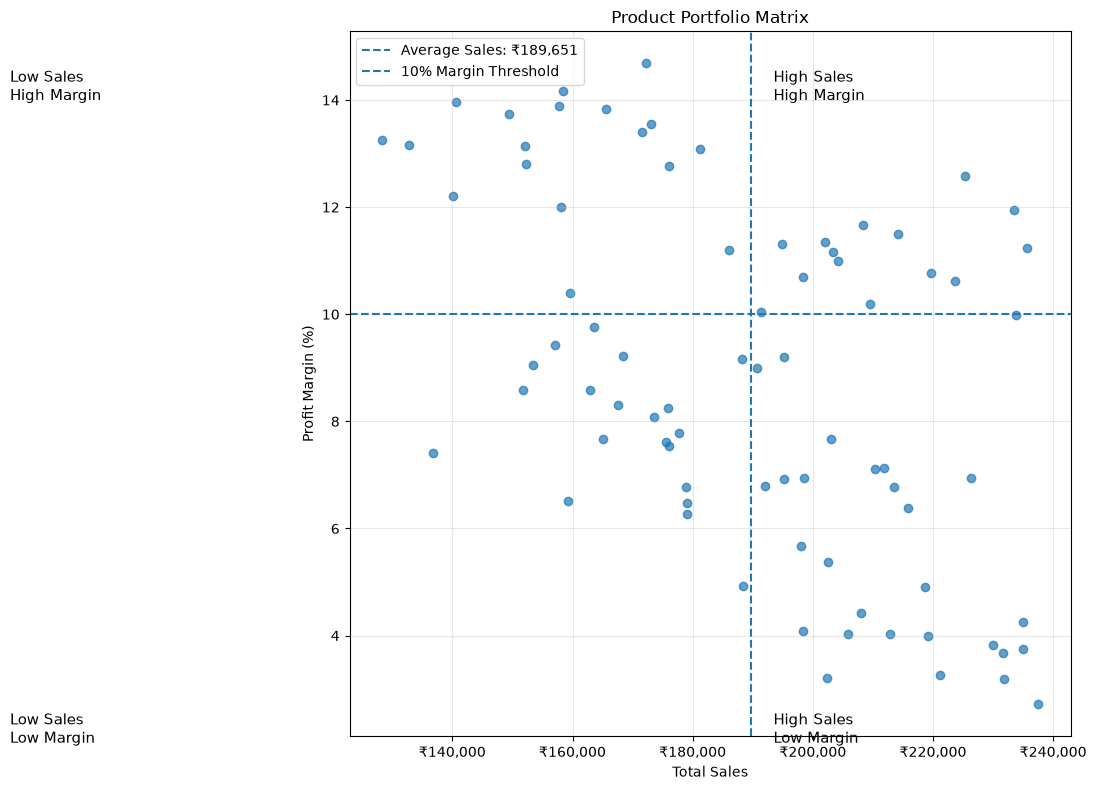

In [46]:
plt.figure(figsize=(12, 8))

plt.scatter(
    Product_Portfolio_Matrix["Total_Sales"],
    Product_Portfolio_Matrix["Profit_Margin_%"],
    alpha=0.7
)

# Reference lines
plt.axvline(
    Avg_Product_Sales,
    linestyle="--",
    label=f"Average Sales: ₹{Avg_Product_Sales:,.0f}"
)

plt.axhline(
    10,
    linestyle="--",
    label="10% Margin Threshold"
)

# Quadrant labels
plt.text(
    Avg_Product_Sales * 1.02,
    14,
    "High Sales\nHigh Margin",
    fontsize=11
)

plt.text(
    Avg_Product_Sales * 1.02,
    2,
    "High Sales\nLow Margin",
    fontsize=11
)

plt.text(
    Avg_Product_Sales * 0.35,
    14,
    "Low Sales\nHigh Margin",
    fontsize=11
)

plt.text(
    Avg_Product_Sales * 0.35,
    2,
    "Low Sales\nLow Margin",
    fontsize=11
)

plt.title("Product Portfolio Matrix")
plt.xlabel("Total Sales")
plt.ylabel("Profit Margin (%)")

plt.gca().xaxis.set_major_formatter(
    ticker.StrMethodFormatter("₹{x:,.0f}")
)

plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [47]:
Low_Sales_Low_Margin = (
    Product_Portfolio_Matrix[
        Product_Portfolio_Matrix["Product_Segment"] == "Low Sales - Low Margin"
    ]
    .sort_values(
        ["Total_Sales", "Profit_Margin_%"],
        ascending=[False, True]
    )
)

display(
    Low_Sales_Low_Margin[
        [
            "Product_Name",
            "Category",
            "Sub_Category",
            "Total_Sales",
            "Total_Profit",
            "Profit_Margin_%"
        ]
    ].style.format({
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Profit_Margin_%": "{:.2f}%"
    })
)

,Product_Name,Category,Sub_Category,Total_Sales,Total_Profit,Profit_Margin_%
21,Earbuds,Electronics,Audio,"₹188,299.31","₹9,261.77",4.92%
2,Bedsheet,Home & Kitchen,Bedding,"₹188,151.42","₹17,246.15",9.17%
16,Cushion Set,Furniture,Furnishings,"₹179,078.75","₹11,590.61",6.47%
55,Rug,Furniture,Furnishings,"₹179,029.00","₹11,241.67",6.28%
45,Office Chair,Furniture,Chairs,"₹178,968.02","₹12,117.02",6.77%
43,Mop,Home & Kitchen,Cleaning,"₹177,736.03","₹13,821.49",7.78%
17,Dining Chair,Furniture,Chairs,"₹176,122.99","₹13,266.59",7.53%
11,Cleaning Kit,Home & Kitchen,Cleaning,"₹175,958.28","₹14,522.49",8.25%
13,Cookware Set,Home & Kitchen,Kitchen,"₹175,513.89","₹13,371.86",7.62%
42,Mixer,Home & Kitchen,Kitchen,"₹173,611.51","₹14,021.93",8.08%


### Product Analytics — Key Insights

**1. Sales leadership does not always translate into profitability.**
Several high-sales products generate relatively low profit margins. For example, USB Hub generated ₹2.37 lakh in sales but only a 2.71% margin, while Shredder generated ₹2.34 lakh with an 11.94% margin.

**2. High Sales–Low Margin is the largest portfolio segment.**
The segment contains 28 products and contributes **39.38% of total product sales**, but its overall profit margin is only **5.49%**. Several Electronics products are particularly low-margin.

**3. Low Sales–High Margin products represent growth opportunities.**
18 products generate **13.06% profit margin** while contributing 18.82% of sales. Most are Clothing products, suggesting that selected high-margin products could potentially be promoted more aggressively.

**4. High Sales–High Margin products show a strong product pattern.**
14 products fall into this segment, generating **₹29.64 lakh sales** with an **11.17% margin**. All 14 are Office Supplies, indicating that this category contains several products that combine strong demand with healthier profitability.

**5. Low Sales–Low Margin products require portfolio review.**
20 products generate **₹33.78 lakh sales** with a **7.84% margin**. These products should be evaluated based on demand, pricing, discounting, costs, and strategic importance before deciding whether to improve, reposition, or reduce their presence.

### Business Recommendations

* Review pricing, discounts, supplier costs, and product-level costs for **High Sales–Low Margin** products.
* Give particular attention to high-volume Electronics products with margins below approximately 4%.
* Increase visibility of selected **Low Sales–High Margin** products through targeted promotions, recommendations, bundles, and cross-selling.
* Study the characteristics of successful **Office Supplies** products to identify pricing or product-mix practices that could be applied elsewhere.
* Review **Low Sales–Low Margin** products before making assortment decisions; use demand and profitability together rather than sales alone.
* Track product performance using both **sales and profit margin** so that revenue growth does not come at the expense of profitability.


### Operations & Shipping Analytics

In [48]:
Portfolio_Shipping = df.copy()

Portfolio_Shipping["Shipping_Days"] = (
    Portfolio_Shipping["Ship_Date"] - Portfolio_Shipping["Order_Date"]
).dt.days

Shipping_Summary = (
    Portfolio_Shipping
    .groupby("Ship_Mode")
    .agg(
        Total_Orders=("Order_ID", "nunique"),
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Avg_Shipping_Days=("Shipping_Days", "mean")
    )
    .reset_index()
)

Shipping_Summary["Profit_Margin_%"] = (
    Shipping_Summary["Total_Profit"]
    / Shipping_Summary["Total_Sales"]
) * 100

Shipping_Summary["Sales_Contribution_%"] = (
    Shipping_Summary["Total_Sales"]
    / Shipping_Summary["Total_Sales"].sum()
) * 100

display(
    Shipping_Summary.style.format({
        "Total_Orders": "{:,.0f}",
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Avg_Shipping_Days": "{:.2f}",
        "Profit_Margin_%": "{:.2f}%",
        "Sales_Contribution_%": "{:.2f}%"
    })
)

,Ship_Mode,Total_Orders,Total_Sales,Total_Profit,Avg_Shipping_Days,Profit_Margin_%,Sales_Contribution_%
0,First Class,"2,947","₹2,226,344.05","₹199,799.46",4.04,8.97%,14.67%
1,Same Day,993,"₹726,601.27","₹65,071.98",4.01,8.96%,4.79%
2,Second Class,"4,947","₹3,754,282.87","₹310,784.05",4.05,8.28%,24.74%
3,Standard Class,"11,113","₹8,464,847.28","₹721,034.23",4.07,8.52%,55.79%


In [49]:
Shipping_Days_Summary = (
    Portfolio_Shipping["Shipping_Days"]
    .describe()
    .to_frame("Value")
)

Shipping_Days_Summary

,Value
count,19940.000000
mean,4.057422
std,1.875711
min,1.000000
25%,3.000000
50%,4.000000
75%,5.000000
max,10.000000


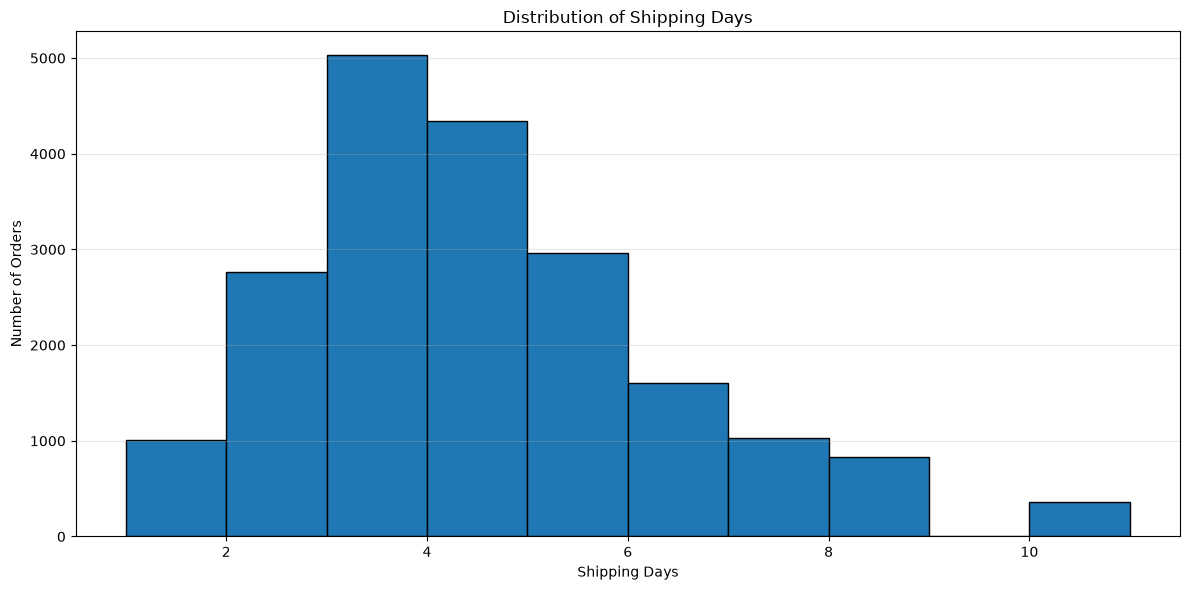

In [50]:
plt.figure(figsize=(12, 6))

plt.hist(
    Portfolio_Shipping["Shipping_Days"].dropna(),
    bins=range(
        int(Portfolio_Shipping["Shipping_Days"].min()),
        int(Portfolio_Shipping["Shipping_Days"].max()) + 2
    ),
    edgecolor="black"
)

plt.title("Distribution of Shipping Days")
plt.xlabel("Shipping Days")
plt.ylabel("Number of Orders")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

In [51]:
Late_Shipping_Orders = Portfolio_Shipping[
    Portfolio_Shipping["Shipping_Days"] > 5
].copy()

Late_Shipping_Summary = pd.DataFrame({
    "Metric": [
        "Late Orders",
        "Late Order %",
        "Late Order Sales",
        "Late Order Profit",
        "Average Shipping Days"
    ],
    "Value": [
        len(Late_Shipping_Orders),
        len(Late_Shipping_Orders) / Portfolio_Shipping["Shipping_Days"].notna().sum() * 100,
        Late_Shipping_Orders["Sales"].sum(),
        Late_Shipping_Orders["Profit"].sum(),
        Late_Shipping_Orders["Shipping_Days"].mean()
    ]
})

display(
    Late_Shipping_Summary.style.format({
        "Value": lambda x: f"{x:,.2f}"
    })
)

,Metric,Value
0,Late Orders,"3,824.00"
1,Late Order %,19.18
2,Late Order Sales,"2,882,737.01"
3,Late Order Profit,"242,092.47"
4,Average Shipping Days,7.08


In [52]:
Late_Shipping_Region = (
    Late_Shipping_Orders
    .groupby("Region")
    .agg(
        Late_Orders=("Order_ID", "nunique"),
        Late_Sales=("Sales", "sum"),
        Late_Profit=("Profit", "sum"),
        Avg_Shipping_Days=("Shipping_Days", "mean")
    )
    .reset_index()
)

Late_Shipping_Region["Late_Order_%"] = (
    Late_Shipping_Region["Late_Orders"]
    / Portfolio_Shipping.groupby("Region")["Order_ID"].nunique()
    .reindex(Late_Shipping_Region["Region"])
    .values
) * 100

display(
    Late_Shipping_Region.style.format({
        "Late_Orders": "{:,.0f}",
        "Late_Sales": "₹{:,.2f}",
        "Late_Profit": "₹{:,.2f}",
        "Avg_Shipping_Days": "{:.2f}",
        "Late_Order_%": "{:.2f}%"
    })
)

,Region,Late_Orders,Late_Sales,Late_Profit,Avg_Shipping_Days,Late_Order_%
0,East,862,"₹642,542.75","₹58,552.97",7.12,18.90%
1,North,"1,014","₹790,184.68","₹66,797.10",7.10,18.79%
2,South,978,"₹721,738.88","₹57,605.40",7.05,19.34%
3,West,970,"₹728,270.70","₹59,137.00",7.06,19.46%


### Shipping Delay Insight

Approximately **19.18% of orders with valid shipping dates took more than 5 days to ship**. These 3,824 delayed orders generated ₹28.83 lakh in sales and had an average shipping time of 7.08 days, compared with the overall average of 4.06 days.

Delayed-order rates were relatively similar across regions, ranging from 18.79% in North to 19.46% in West. This suggests that shipping delays are **not strongly concentrated in a single region** within this dataset.

**Business Action:** Investigate operational factors such as shipping mode, fulfillment process, warehouse handling, and order characteristics rather than focusing only on geographic regions. Monitor the delayed-order rate as an operational KPI.


In [53]:
Shipping_Mode_Delay = (
    Portfolio_Shipping[
        Portfolio_Shipping["Shipping_Days"].notna()
    ]
    .groupby("Ship_Mode")
    .agg(
        Total_Orders=("Order_ID", "nunique"),
        Avg_Shipping_Days=("Shipping_Days", "mean")
    )
    .reset_index()
)

Late_By_Ship_Mode = (
    Late_Shipping_Orders
    .groupby("Ship_Mode")
    .agg(
        Late_Orders=("Order_ID", "nunique"),
        Late_Sales=("Sales", "sum"),
        Late_Profit=("Profit", "sum")
    )
    .reset_index()
)

Shipping_Mode_Delay = Shipping_Mode_Delay.merge(
    Late_By_Ship_Mode,
    on="Ship_Mode",
    how="left"
)

Shipping_Mode_Delay[
    ["Late_Orders", "Late_Sales", "Late_Profit"]
] = Shipping_Mode_Delay[
    ["Late_Orders", "Late_Sales", "Late_Profit"]
].fillna(0)

Shipping_Mode_Delay["Late_Order_%"] = (
    Shipping_Mode_Delay["Late_Orders"]
    / Shipping_Mode_Delay["Total_Orders"]
) * 100

display(
    Shipping_Mode_Delay.style.format({
        "Total_Orders": "{:,.0f}",
        "Late_Orders": "{:,.0f}",
        "Late_Sales": "₹{:,.2f}",
        "Late_Profit": "₹{:,.2f}",
        "Avg_Shipping_Days": "{:.2f}",
        "Late_Order_%": "{:.2f}%"
    })
)

,Ship_Mode,Total_Orders,Avg_Shipping_Days,Late_Orders,Late_Sales,Late_Profit,Late_Order_%
0,First Class,"2,937",4.04,557,"₹436,272.98","₹36,861.13",18.96%
1,Same Day,991,4.01,177,"₹120,966.57","₹11,741.43",17.86%
2,Second Class,"4,930",4.05,930,"₹658,572.29","₹56,410.16",18.86%
3,Standard Class,"11,082",4.07,"2,160","₹1,666,925.17","₹137,079.75",19.49%


### Shipping Mode Delay Insight

Delayed-order rates were relatively similar across all shipping modes, ranging from 17.86% for Same Day to 19.49% for Standard Class. Standard Class had the highest late-order rate and the largest number of delayed orders because it also handled the highest order volume.

The relatively small difference between shipping modes suggests that shipping mode alone does not explain the majority of delays. Operational factors beyond the selected shipping mode should therefore be investigated.

**Business Action:** Monitor delay rates by shipping mode, but also investigate fulfillment, warehouse processing, order characteristics, and regional operational factors before changing shipping-mode strategy.


In [54]:
Region_Ship_Mode_Delay = (
    Portfolio_Shipping[
        Portfolio_Shipping["Shipping_Days"].notna()
    ]
    .groupby(["Region", "Ship_Mode"])
    .agg(
        Total_Orders=("Order_ID", "nunique"),
        Late_Orders=("Shipping_Days", lambda x: (x > 5).sum()),
        Avg_Shipping_Days=("Shipping_Days", "mean")
    )
    .reset_index()
)

Region_Ship_Mode_Delay["Late_Order_%"] = (
    Region_Ship_Mode_Delay["Late_Orders"]
    / Region_Ship_Mode_Delay["Total_Orders"]
) * 100

display(
    Region_Ship_Mode_Delay.style.format({
        "Total_Orders": "{:,.0f}",
        "Late_Orders": "{:,.0f}",
        "Avg_Shipping_Days": "{:.2f}",
        "Late_Order_%": "{:.2f}%"
    })
)

,Region,Ship_Mode,Total_Orders,Late_Orders,Avg_Shipping_Days,Late_Order_%
0,East,First Class,684,120,3.99,17.54%
1,East,Same Day,225,36,3.92,16.00%
2,East,Second Class,"1,115",201,4.00,18.03%
3,East,Standard Class,"2,525",505,4.08,20.00%
4,North,First Class,798,144,4.04,18.05%
5,North,Same Day,264,51,3.95,19.32%
6,North,Second Class,"1,367",256,4.02,18.73%
7,North,Standard Class,"2,952",563,4.05,19.07%
8,South,First Class,753,160,4.17,21.25%
9,South,Same Day,257,38,3.93,14.79%


### Operations & Shipping Analytics — Key Insights

**1. Standard Class is the dominant shipping mode.**
Standard Class handles 11,113 orders and contributes 55.79% of total sales. Its average recorded shipping time is 4.07 days.

**2. Shipping performance is relatively similar across shipping modes.**
Average recorded shipping times range from 4.01 to 4.07 days, while delayed-order rates range from 17.86% to 19.49%. The differences are relatively small.

**3. Approximately one-fifth of orders are delayed.**
3,824 of 19,940 orders with valid shipping dates took more than 5 days, representing 19.18% of eligible orders. These delayed orders generated approximately ₹28.83 lakh in sales.

**4. Delays are not strongly concentrated in one region.**
Regional delayed-order rates range from 18.79% to 19.46%, indicating relatively similar delay levels across regions.

**5. Region–shipping mode combinations show some variation, but no dominant pattern.**
The highest observed combination was South + First Class at 21.25%, while the largest order-volume combination, North + Standard Class, had a 19.07% delay rate.

**6. The dataset contains a shipping-definition issue.**
The recorded `Same Day` shipping mode has an average Order_Date-to-Ship_Date difference of approximately 4 days. Therefore, the analysis measures the difference between recorded order and ship dates rather than actual delivery time. The `Same Day` label and date behavior should be validated before making operational conclusions.

### Business Recommendations

* Monitor **late-order rate** as an operational KPI rather than relying only on


In [55]:
Portfolio_Payment = (
    df.groupby("Payment_Mode")
      .agg(
          Total_Orders=("Order_ID", "nunique"),
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Customers=("Customer_ID", "nunique")
      )
      .reset_index()
)

Portfolio_Payment["Profit_Margin_%"] = (
    Portfolio_Payment["Total_Profit"]
    / Portfolio_Payment["Total_Sales"]
) * 100

Portfolio_Payment["Sales_Contribution_%"] = (
    Portfolio_Payment["Total_Sales"]
    / Portfolio_Payment["Total_Sales"].sum()
) * 100

Portfolio_Payment["AOV"] = (
    Portfolio_Payment["Total_Sales"]
    / Portfolio_Payment["Total_Orders"]
)

display(
    Portfolio_Payment.style.format({
        "Total_Orders": "{:,.0f}",
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Total_Customers": "{:,.0f}",
        "Profit_Margin_%": "{:.2f}%",
        "Sales_Contribution_%": "{:.2f}%",
        "AOV": "₹{:,.2f}"
    })
)

,Payment_Mode,Total_Orders,Total_Sales,Total_Profit,Total_Customers,Profit_Margin_%,Sales_Contribution_%,AOV
0,Cash on Delivery,"1,976","₹1,564,770.96","₹138,919.53","1,550",8.88%,10.31%,₹791.89
1,Credit Card,"5,352","₹4,029,909.16","₹349,465.62","2,961",8.67%,26.56%,₹752.97
2,Debit Card,"4,927","₹3,660,964.62","₹301,681.12","2,807",8.24%,24.13%,₹743.04
3,Net Banking,"2,570","₹1,969,578.87","₹172,111.84","1,903",8.74%,12.98%,₹766.37
4,UPI,"5,095","₹3,885,092.82","₹327,486.75","2,876",8.43%,25.61%,₹762.53
5,Unknown,80,"₹61,759.04","₹7,024.86",80,11.37%,0.41%,₹771.99


In [56]:
Low_Sales_Low_Margin = (
    Product_Portfolio_Matrix[
        Product_Portfolio_Matrix["Product_Segment"] == "Low Sales - Low Margin"
    ]
    .sort_values(
        ["Profit_Margin_%", "Total_Sales"],
        ascending=[True, False]
    )
)

display(
    Low_Sales_Low_Margin[
        [
            "Product_Name",
            "Category",
            "Sub_Category",
            "Total_Sales",
            "Total_Profit",
            "Profit_Margin_%"
        ]
    ].style.format({
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Profit_Margin_%": "{:.2f}%"
    })
)

,Product_Name,Category,Sub_Category,Total_Sales,Total_Profit,Profit_Margin_%
21,Earbuds,Electronics,Audio,"₹188,299.31","₹9,261.77",4.92%
55,Rug,Furniture,Furnishings,"₹179,029.00","₹11,241.67",6.28%
16,Cushion Set,Furniture,Furnishings,"₹179,078.75","₹11,590.61",6.47%
5,Bookshelf,Furniture,Storage,"₹159,262.19","₹10,377.47",6.52%
45,Office Chair,Furniture,Chairs,"₹178,968.02","₹12,117.02",6.77%
65,Storage Jars,Home & Kitchen,Kitchen,"₹136,774.80","₹10,123.07",7.40%
17,Dining Chair,Furniture,Chairs,"₹176,122.99","₹13,266.59",7.53%
13,Cookware Set,Home & Kitchen,Kitchen,"₹175,513.89","₹13,371.86",7.62%
50,Pillow Set,Home & Kitchen,Bedding,"₹165,096.42","₹12,678.59",7.68%
43,Mop,Home & Kitchen,Cleaning,"₹177,736.03","₹13,821.49",7.78%


### Product Portfolio Insight

The product portfolio shows a clear difference between sales volume and profitability. The largest segment is **High Sales–Low Margin**, containing 28 products and contributing **39.38% of total product sales**, but generating only a **5.49% profit margin**.

In contrast, the **Low Sales–High Margin** segment contains 18 products and generates a **13.06% profit margin**, indicating that several lower-volume products have stronger profitability.

The **Low Sales–Low Margin** segment contains 20 products and contributes **22.27% of sales** with a **7.84% margin**. Most products in this segment belong to Home & Kitchen and Furniture.

**Business Action:** Prioritize margin improvement for high-sales, low-margin products by reviewing pricing, discounts, supplier costs, and product mix. At the same time, evaluate selected low-sales, high-margin products for targeted promotions, cross-selling, and increased visibility to determine whether sales can be expanded while preserving margins.


In [57]:
Portfolio_Shipping = df.copy()

Portfolio_Shipping["Shipping_Days"] = (
    Portfolio_Shipping["Ship_Date"]
    - Portfolio_Shipping["Order_Date"]
).dt.days

Portfolio_Shipping["Late_Order"] = (
    Portfolio_Shipping["Shipping_Days"] > 5
)

Total_Valid_Shipping_Orders = (
    Portfolio_Shipping["Shipping_Days"].notna().sum()
)

Total_Late_Orders = (
    Portfolio_Shipping["Late_Order"]
    & Portfolio_Shipping["Shipping_Days"].notna()
).sum()

Late_Order_Percentage = (
    Total_Late_Orders
    / Total_Valid_Shipping_Orders
) * 100

Late_Order_Sales = Portfolio_Shipping.loc[
    Portfolio_Shipping["Late_Order"],
    "Sales"
].sum()

Late_Order_Profit = Portfolio_Shipping.loc[
    Portfolio_Shipping["Late_Order"],
    "Profit"
].sum()

Average_Shipping_Days = (
    Portfolio_Shipping["Shipping_Days"].mean()
)

Overall_Shipping_Summary = pd.DataFrame({
    "Metric": [
        "Valid Shipping Orders",
        "Average Shipping Days",
        "Late Orders",
        "Late Order %",
        "Late Order Sales",
        "Late Order Profit"
    ],
    "Value": [
        Total_Valid_Shipping_Orders,
        Average_Shipping_Days,
        Total_Late_Orders,
        Late_Order_Percentage,
        Late_Order_Sales,
        Late_Order_Profit
    ]
})

display(
    Overall_Shipping_Summary.style.format({
        "Value": "{:,.2f}"
    })
)

,Metric,Value
0,Valid Shipping Orders,"19,940.00"
1,Average Shipping Days,4.06
2,Late Orders,"3,824.00"
3,Late Order %,19.18
4,Late Order Sales,"2,882,737.01"
5,Late Order Profit,"242,092.47"


### Overall Shipping Performance

The analysis covers **19,940 valid shipping orders** with an average delivery time of **4.06 days**.

A total of **3,824 orders (19.18%)** were classified as late. These delayed orders represent approximately **₹28.83 lakh in sales** and **₹2.42 lakh in profit**, showing that delivery delays affect a meaningful volume of business transactions.

**Business Action:** Monitor delayed orders by region, shipping mode, destination, and operational factors such as processing and carrier performance. The analysis should focus on identifying the underlying drivers of delays rather than assuming that a single shipping mode or region is responsible.


In [58]:
Shipping_Mode_Performance = (
    Portfolio_Shipping
    .groupby("Ship_Mode")
    .agg(
        Total_Orders=("Order_ID", "nunique"),
        Total_Sales=("Sales", "sum"),
        Total_Profit=("Profit", "sum"),
        Avg_Shipping_Days=("Shipping_Days", "mean")
    )
    .reset_index()
)

Shipping_Mode_Performance["Profit_Margin_%"] = (
    Shipping_Mode_Performance["Total_Profit"]
    / Shipping_Mode_Performance["Total_Sales"]
) * 100

Shipping_Mode_Performance["Sales_Contribution_%"] = (
    Shipping_Mode_Performance["Total_Sales"]
    / Shipping_Mode_Performance["Total_Sales"].sum()
) * 100

display(
    Shipping_Mode_Performance.style.format({
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Avg_Shipping_Days": "{:.2f}",
        "Profit_Margin_%": "{:.2f}%",
        "Sales_Contribution_%": "{:.2f}%"
    })
)

,Ship_Mode,Total_Orders,Total_Sales,Total_Profit,Avg_Shipping_Days,Profit_Margin_%,Sales_Contribution_%
0,First Class,2947,"₹2,226,344.05","₹199,799.46",4.04,8.97%,14.67%
1,Same Day,993,"₹726,601.27","₹65,071.98",4.01,8.96%,4.79%
2,Second Class,4947,"₹3,754,282.87","₹310,784.05",4.05,8.28%,24.74%
3,Standard Class,11113,"₹8,464,847.28","₹721,034.23",4.07,8.52%,55.79%


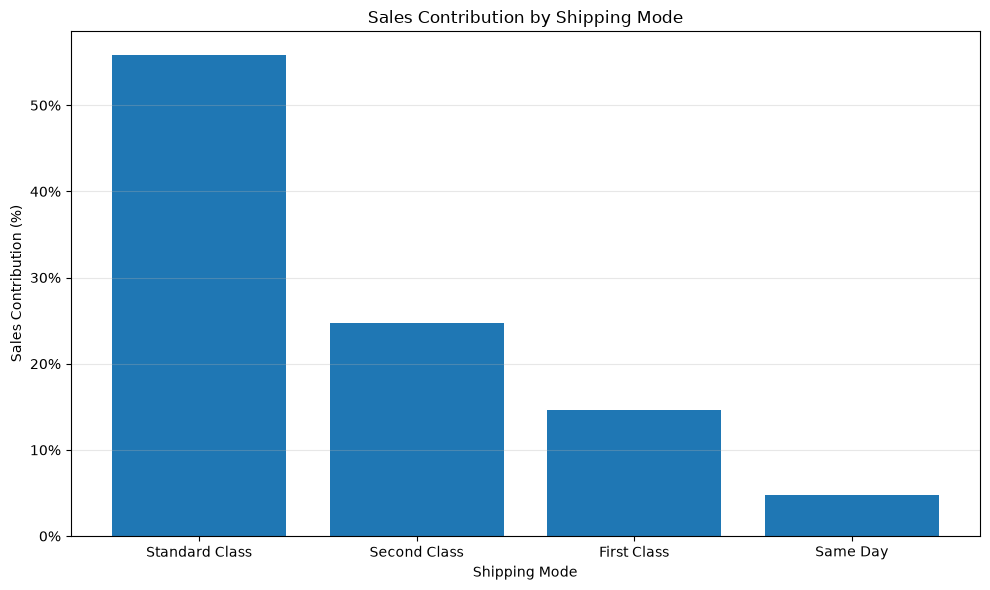

In [59]:
Shipping_Mode_Chart = Shipping_Mode_Performance.sort_values(
    "Sales_Contribution_%",
    ascending=False
)

plt.figure(figsize=(10, 6))

plt.bar(
    Shipping_Mode_Chart["Ship_Mode"],
    Shipping_Mode_Chart["Sales_Contribution_%"]
)

plt.title("Sales Contribution by Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Sales Contribution (%)")

plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:.0f}%")
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Shipping Mode Performance

**Standard Class** is the dominant shipping mode, accounting for **55.79% of total sales**, followed by **Second Class at 24.74%**. First Class contributes **14.67%**, while Same Day contributes **4.79%**.

Despite the different shipping-mode labels, average shipping times are very similar, ranging from **4.01 to 4.07 days**. Profit margins are also relatively close across the major modes, ranging from **8.28% to 8.97%**.

**Business Action:** Since Standard Class represents the largest share of sales, its operational performance should receive close monitoring. The similar average shipping times across modes also suggest that delivery performance should be investigated using additional factors such as destination, processing time, carrier performance, and order volume rather than shipping mode alone.


In [60]:
Regional_Late_Orders = (
    Portfolio_Shipping
    .groupby("Region")
    .agg(
        Total_Orders=("Order_ID", "nunique"),
        Late_Orders=("Late_Order", "sum"),
        Late_Order_Sales=("Sales", lambda x:
            x[Portfolio_Shipping.loc[x.index, "Late_Order"]].sum()
        ),
        Late_Order_Profit=("Profit", lambda x:
            x[Portfolio_Shipping.loc[x.index, "Late_Order"]].sum()
        ),
        Avg_Late_Shipping_Days=("Shipping_Days", lambda x:
            x[Portfolio_Shipping.loc[x.index, "Late_Order"]].mean()
        )
    )
    .reset_index()
)

Regional_Late_Orders["Late_Order_%"] = (
    Regional_Late_Orders["Late_Orders"]
    / Regional_Late_Orders["Total_Orders"]
) * 100

display(
    Regional_Late_Orders.style.format({
        "Late_Order_Sales": "₹{:,.2f}",
        "Late_Order_Profit": "₹{:,.2f}",
        "Avg_Late_Shipping_Days": "{:.2f}",
        "Late_Order_%": "{:.2f}%"
    })
)

,Region,Total_Orders,Late_Orders,Late_Order_Sales,Late_Order_Profit,Avg_Late_Shipping_Days,Late_Order_%
0,East,4562,862,"₹642,542.75","₹58,552.97",7.12,18.90%
1,North,5397,1014,"₹790,184.68","₹66,797.10",7.10,18.79%
2,South,5056,978,"₹721,738.88","₹57,605.40",7.05,19.34%
3,West,4985,970,"₹728,270.70","₹59,137.00",7.06,19.46%


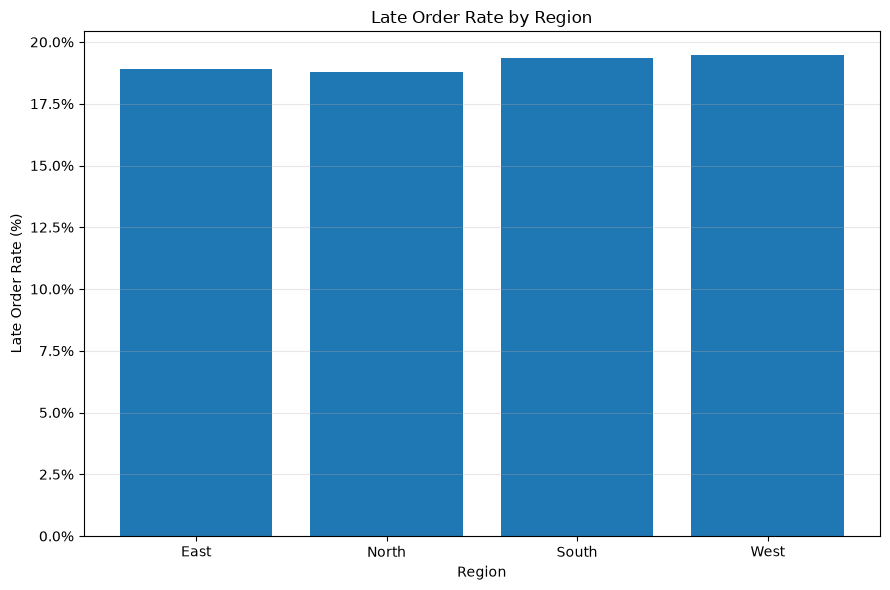

In [61]:
plt.figure(figsize=(9, 6))

plt.bar(
    Regional_Late_Orders["Region"],
    Regional_Late_Orders["Late_Order_%"]
)

plt.title("Late Order Rate by Region")
plt.xlabel("Region")
plt.ylabel("Late Order Rate (%)")

plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:.1f}%")
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Regional Late-Order Performance

Late-order rates are relatively similar across all four regions, ranging from **18.79% in North to 19.46% in West**. This indicates that delayed orders are broadly distributed across the business rather than being concentrated in a single region.

North has the highest number of late orders at **1,014**, but this occurs alongside the highest order volume. West has the highest late-order rate at **19.46%**, while North has the lowest at **18.79%**.

**Business Action:** Since regional differences are relatively small, investigate additional operational factors such as destination/state, warehouse processing time, carrier performance, order volume, and peak periods to identify the underlying drivers of delayed orders.


In [62]:
Region_Shipping_Late_Rate = (
    Portfolio_Shipping
    .groupby(["Region", "Ship_Mode"])
    .agg(
        Total_Orders=("Order_ID", "nunique"),
        Late_Orders=("Late_Order", "sum"),
        Avg_Shipping_Days=("Shipping_Days", "mean")
    )
    .reset_index()
)

Region_Shipping_Late_Rate["Late_Order_%"] = (
    Region_Shipping_Late_Rate["Late_Orders"]
    / Region_Shipping_Late_Rate["Total_Orders"]
) * 100

display(
    Region_Shipping_Late_Rate.style.format({
        "Avg_Shipping_Days": "{:.2f}",
        "Late_Order_%": "{:.2f}%"
    })
)

,Region,Ship_Mode,Total_Orders,Late_Orders,Avg_Shipping_Days,Late_Order_%
0,East,First Class,688,120,3.99,17.44%
1,East,Same Day,225,36,3.92,16.00%
2,East,Second Class,1118,201,4.00,17.98%
3,East,Standard Class,2531,505,4.08,19.95%
4,North,First Class,802,144,4.04,17.96%
5,North,Same Day,265,51,3.95,19.25%
6,North,Second Class,1369,256,4.02,18.70%
7,North,Standard Class,2961,563,4.05,19.01%
8,South,First Class,755,160,4.17,21.19%
9,South,Same Day,258,38,3.93,14.73%


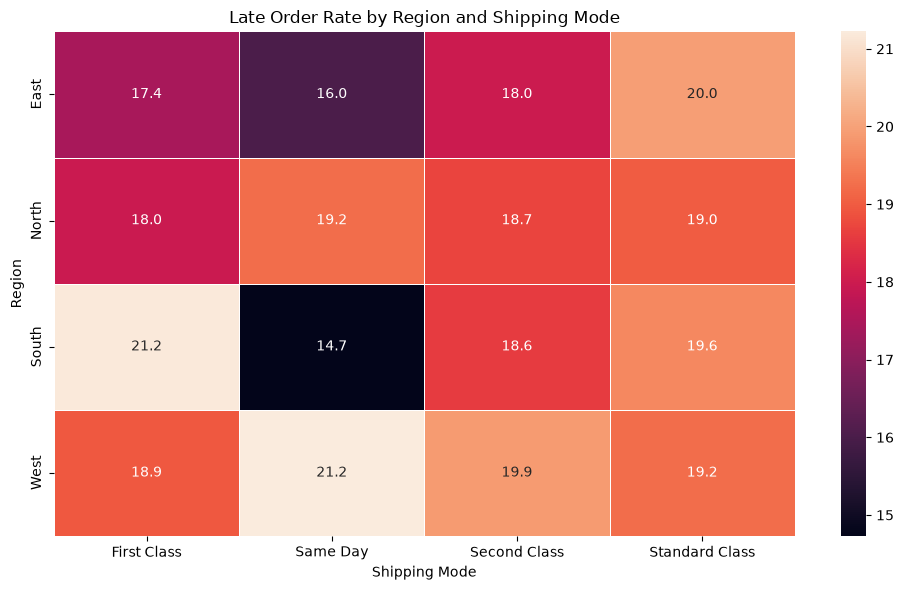

In [63]:
Shipping_Heatmap = (
    Region_Shipping_Late_Rate
    .pivot(
        index="Region",
        columns="Ship_Mode",
        values="Late_Order_%"
    )
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    Shipping_Heatmap,
    annot=True,
    fmt=".1f",
    linewidths=0.5
)

plt.title("Late Order Rate by Region and Shipping Mode")
plt.xlabel("Shipping Mode")
plt.ylabel("Region")

plt.tight_layout()
plt.show()

### Operations & Shipping Insight

The analysis shows an average shipping time of **4.06 days**, with **19.18% of valid shipping orders classified as late**. These late orders represent approximately **₹28.83 lakh in sales**.

Shipping-mode performance is relatively similar, with average shipping times ranging from **4.01 to 4.07 days**. Standard Class accounts for the largest share of sales at **55.79%**, making its operational performance important because of its high transaction volume.

Regional late-order rates are also relatively close, ranging from **18.79% to 19.46%**. When region and shipping mode are combined, some individual combinations show higher or lower late rates, but no single combination explains the overall pattern.

**Business Action:** Investigate delays using additional operational dimensions such as destination/state, warehouse processing time, carrier performance, order volume, and peak periods. Focus on identifying the underlying drivers of delays rather than attributing the issue to one shipping mode or region.


In [64]:
Portfolio_Payment = (
    df.groupby("Payment_Mode")
      .agg(
          Total_Orders=("Order_ID", "nunique"),
          Total_Sales=("Sales", "sum"),
          Total_Profit=("Profit", "sum"),
          Total_Customers=("Customer_ID", "nunique")
      )
      .reset_index()
)

Portfolio_Payment["Profit_Margin_%"] = (
    Portfolio_Payment["Total_Profit"]
    / Portfolio_Payment["Total_Sales"]
) * 100

Portfolio_Payment["Sales_Contribution_%"] = (
    Portfolio_Payment["Total_Sales"]
    / Portfolio_Payment["Total_Sales"].sum()
) * 100

Portfolio_Payment["AOV"] = (
    Portfolio_Payment["Total_Sales"]
    / Portfolio_Payment["Total_Orders"]
)

display(
    Portfolio_Payment.style.format({
        "Total_Sales": "₹{:,.2f}",
        "Total_Profit": "₹{:,.2f}",
        "Profit_Margin_%": "{:.2f}%",
        "Sales_Contribution_%": "{:.2f}%",
        "AOV": "₹{:,.2f}"
    })
)

,Payment_Mode,Total_Orders,Total_Sales,Total_Profit,Total_Customers,Profit_Margin_%,Sales_Contribution_%,AOV
0,Cash on Delivery,1976,"₹1,564,770.96","₹138,919.53",1550,8.88%,10.31%,₹791.89
1,Credit Card,5352,"₹4,029,909.16","₹349,465.62",2961,8.67%,26.56%,₹752.97
2,Debit Card,4927,"₹3,660,964.62","₹301,681.12",2807,8.24%,24.13%,₹743.04
3,Net Banking,2570,"₹1,969,578.87","₹172,111.84",1903,8.74%,12.98%,₹766.37
4,UPI,5095,"₹3,885,092.82","₹327,486.75",2876,8.43%,25.61%,₹762.53
5,Unknown,80,"₹61,759.04","₹7,024.86",80,11.37%,0.41%,₹771.99


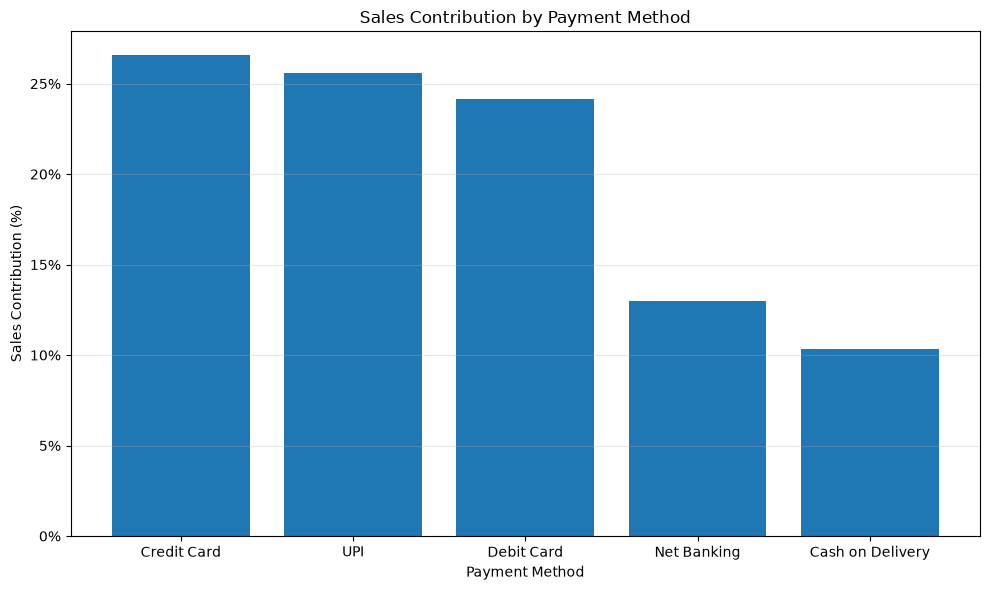

In [65]:
Payment_Chart = Portfolio_Payment[
    Portfolio_Payment["Payment_Mode"] != "Unknown"
].sort_values(
    "Sales_Contribution_%",
    ascending=False
)

plt.figure(figsize=(10, 6))

plt.bar(
    Payment_Chart["Payment_Mode"],
    Payment_Chart["Sales_Contribution_%"]
)

plt.title("Sales Contribution by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Sales Contribution (%)")

plt.gca().yaxis.set_major_formatter(
    ticker.StrMethodFormatter("{x:.0f}%")
)

plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

### Payment Method Performance

Credit Card is the largest payment method by sales contribution at **26.56%**, followed by **UPI at 25.61%** and **Debit Card at 24.13%**. Together, these three methods account for **76.30% of total sales**.

Profit margins across the major payment methods are relatively close, ranging from **8.24% to 8.88%**, indicating that the observed profitability difference between payment methods is limited in this dataset.

Cash on Delivery has the highest AOV among the major payment methods at **₹791.89**, compared with **₹752.97 for Credit Card** and **₹762.53 for UPI**.

**Business Action:** Continue supporting the major payment methods because they represent the majority of sales. Monitor transaction costs, payment failures, refunds, and conversion rates before making payment-method-specific changes. Improve payment-data completeness where possible, although the Unknown category represents only 0.41% of sales.


In [66]:
Business_Risks = pd.DataFrame({
    "Business_Risk": [
        "High-sales products with weak margins",
        "High-sales customers with low margins",
        "Delayed orders",
        "Low-sales high-margin products",
        "Regional sales imbalance",
        "High dependence on major payment methods"
    ],
    
    "Evidence": [
        "28 products contribute 39.38% of sales with a 5.49% profit margin",
        "334 customers generate above-average sales but average only 1.97% margin",
        "3,824 orders (19.18%) are classified as late",
        "18 products generate a 13.06% margin but have below-average sales",
        "North has the highest sales while East has the lowest sales",
        "Credit Card, UPI and Debit Card together contribute 76.30% of sales"
    ],
    
    "Business_Action": [
        "Review pricing, discounts, supplier costs and product mix",
        "Review pricing, discounts, product mix and cost-to-serve",
        "Investigate destination, processing time and carrier performance",
        "Test targeted promotions, bundles and cross-selling",
        "Investigate products, customers and categories driving regional differences",
        "Monitor payment costs, failures, refunds and conversion rates"
    ]
})

display(Business_Risks)

,Business_Risk,Evidence,Business_Action
0,High-sales products with weak margins,28 products contribute 39.38% of sales with a ...,"Review pricing, discounts, supplier costs and ..."
1,High-sales customers with low margins,334 customers generate above-average sales but...,"Review pricing, discounts, product mix and cos..."
2,Delayed orders,"3,824 orders (19.18%) are classified as late","Investigate destination, processing time and c..."
3,Low-sales high-margin products,18 products generate a 13.06% margin but have ...,"Test targeted promotions, bundles and cross-se..."
4,Regional sales imbalance,North has the highest sales while East has the...,"Investigate products, customers and categories..."
5,High dependence on major payment methods,"Credit Card, UPI and Debit Card together contr...","Monitor payment costs, failures, refunds and c..."


## Executive Recommendations

Based on the analysis of sales, profitability, customers, products, regions, shipping operations, and payment methods, the following actions should be prioritized:

### 1. Improve margins on high-sales products

The largest product segment is **High Sales–Low Margin**, representing **39.38% of product sales** with a **5.49% profit margin**.

**Recommendation:** Review pricing, discount levels, supplier costs, and product mix, particularly for high-volume Electronics products with very low margins.

### 2. Improve profitability of high-value customers

A group of **334 customers** generates above-average sales while maintaining an average profit margin of only **1.97%**.

**Recommendation:** Evaluate customer-level pricing, discounts, product mix, and cost-to-serve to improve profitability without unnecessarily reducing sales.

### 3. Investigate delayed orders

**3,824 orders (19.18%)** were classified as late, representing approximately **₹28.83 lakh in sales**.

**Recommendation:** Investigate delays by destination, state, warehouse processing time, carrier performance, order volume, and peak periods.

### 4. Expand selected high-margin products

The **Low Sales–High Margin** segment contains **18 products** with an average margin of **13.06%**.

**Recommendation:** Test targeted promotions, bundles, recommendations, and cross-selling to determine whether selected products can increase sales while maintaining their stronger margins.

### 5. Investigate regional sales differences

North generated the highest regional sales while East generated the lowest.

**Recommendation:** Compare the underlying product, customer, and category mix across regions to identify the factors contributing to the sales differe


# Executive Summary

This project analyzes **20,000 cleaned e-commerce transactions** to evaluate overall business performance across sales, profitability, customers, products, regions, shipping operations, and payment methods.

### Overall Performance

The business generated approximately **₹1.52 crore in sales** and **₹12.97 lakh in profit**, resulting in an overall profit margin of **8.55%**. The dataset contains **3,982 customers** and an average order value of approximately **₹758.60**.

### Key Business Findings

**Product profitability is an important area of attention.** The High Sales–Low Margin product segment contributes **39.38% of product sales** but generates only a **5.49% profit margin**. Several high-volume Electronics products have particularly low margins.

**Customer revenue does not always translate into strong profitability.** A group of **334 above-average-sales customers** has an average profit margin of only **1.97%**, indicating an opportunity to improve the profitability of existing high-value relationships.

**The customer base is strongly repeat-oriented.** Approximately **96.26% of customers made more than one purchase**, while 3.74% purchased only once.

**Shipping performance requires operational monitoring.** Average shipping time is **4.06 days**, while **19.18% of valid shipping orders were classified as late**. These orders repre
